In [1]:
## In this example, we will study output data frame from pandora.py configuration
#### 1. Opening each data frame and check structure
#### 2. Collect POT and scale factor to the target POT
#### 3. Merge evtdf and mcnudf for further study
#### 4. Draw some plots for each slice and for each pfp

import os
import sys
print('Importing cafpyana utils...')
cafpyana_root = "/home/lpelegri/cafpyana"
# Add CAFpyana to the Python search path -- this will allow you to import cafpyana modules
sys.path.insert(0, cafpyana_root)

import lmfit
import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd

print("Loading")
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec

from analysis_village.unfolding.wienersvd import *
from analysis_village.unfolding.unfolding_inputs import *

# Add the head direcoty to sys.path
workspace_root = os.getcwd()  
sys.path.insert(0, workspace_root + "/../../")


from analysis_village.cc1pi.var_configs import *

from analysis_village.cc1pi.HelperFunctions import HelperFunctions
from analysis_village.cc1pi.Constants import CTE as CTE
from analysis_village.cc1pi.CutMasks.CutMasks import *
from analysis_village.cc1pi.CutMasks.MaskUtils import *
from analysis_village.cc1pi.DataFrameUtils import DFCleaning
from analysis_village.cc1pi.DataFrameUtils.DFLoading import *
from analysis_village.cc1pi.GraphUtils.GraphsUtils import *
from analysis_village.cc1pi.GraphUtils.Utils import *

# import this repo's classes
import pyanalib.pandas_helpers as ph
import pyanalib.split_df_helpers as splh
import pyanalib.stat_helpers as sh

from pyanalib.split_df_helpers import *
from analysis_village.cc1pi.systematics.final_variable_configs import VariableConfig
from analysis_village.cc1pi.systematics.utils import *
from analysis_village.cc1pi.systematics.constants import *
from pyanalib.covariance import *
from analysis_village.cc1pi.DataFrameUtils.DFLoading import *
from cols_to_keep import *

from analysis_village.cc1pi.TLExtensionMethod.GaussianFactorFittingUtils import *

np.seterr(divide='ignore', invalid='ignore', over='ignore')

Importing cafpyana utils...
Loading
Importing cafpyana utils...
data_tot_pot: 4.448e+18
Integrated flux: 6.724e+10
# of targets:  1.2208234852399102e+30
xsec unit:  1.2182117569332784e-41


/home/lpelegri/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/ROOT/__init__.py:222: UserWarning: 
This distribution of ROOT is in alpha stage. Feedback is welcome and appreciated. Feel free to reach out to the user forum for questions and general feedback at https://root-forum.cern.ch or to submit an issue at https://github.com/root-project/root/issues. Do not rely on this distribution for production purposes.

  warnings.warn(


{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

In [2]:
import os, glob

base_path = "."  # match your existing base_path

# Remove every ACLiC-generated artifact for both classes
patterns = [
    "PhysdEdx_cpp*", "Hypfit_cpp*",
    "PhysdEdx_ACLiC_dict*", "Hypfit_ACLiC_dict*",
    "*.pcm", "*.d",
]
for pat in patterns:
    for f in glob.glob(os.path.join(base_path, pat)):
        print("removing", f)
        os.remove(f)

removing ./PhysdEdx_cpp.so
removing ./PhysdEdx_cpp_ACLiC_dict_rdict.pcm
removing ./PhysdEdx_cpp.d
removing ./Hypfit_cpp_ACLiC_dict_rdict.pcm
removing ./Hypfit_cpp.so
removing ./Hypfit_cpp.d


keys in /exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_stopping.df
Keys: ['/hdr_0', '/hdr_1', '/histgenevtdf_0', '/histgenevtdf_1', '/histpotdf_0', '/histpotdf_1', '/hit0_0', '/hit0_1', '/hit1_0', '/hit1_1', '/hit2_0', '/hit2_1', '/pfp_0', '/pfp_1', '/split']
n_split: 2


hdr: 100%|██████████| 2/2 [00:00<00:00,  3.36it/s]


5.6275612e+20
duplication for /exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_stopping.df


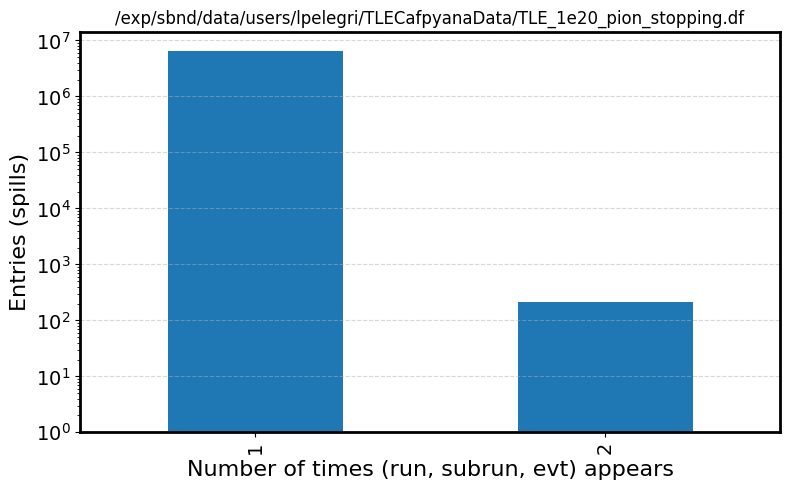

splits: 100%|██████████| 2/2 [00:38<00:00, 19.15s/it]


    shrink_df: 0.009 GB -> 0.003 GB
    shrink_df: 0.015 GB -> 0.015 GB
    shrink_df: 0.129 GB -> 0.122 GB
    shrink_df: 0.125 GB -> 0.119 GB
    shrink_df: 0.137 GB -> 0.130 GB
loaded!
keys in /exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_data.df
Keys: ['/hdr_0', '/hdr_1', '/histgenevtdf_0', '/histgenevtdf_1', '/histpotdf_0', '/histpotdf_1', '/hit0_0', '/hit0_1', '/hit1_0', '/hit1_1', '/hit2_0', '/hit2_1', '/pfp_0', '/pfp_1', '/pot_0', '/pot_1', '/split']
n_split: 2


hdr: 100%|██████████| 2/2 [00:00<00:00, 11.16it/s]


8.370603e+19
duplication for /exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_data.df


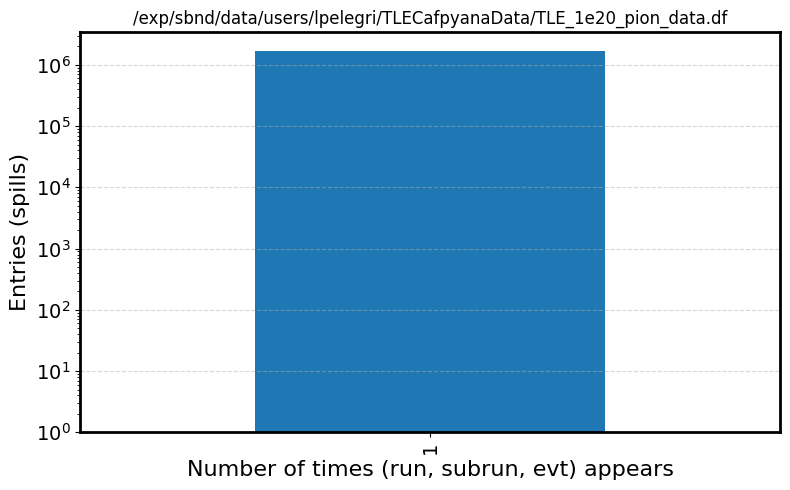

splits: 100%|██████████| 2/2 [00:08<00:00,  4.44s/it]


    shrink_df: 0.001 GB -> 0.000 GB
    shrink_df: 0.002 GB -> 0.002 GB
    shrink_df: 0.018 GB -> 0.017 GB
    shrink_df: 0.017 GB -> 0.016 GB
    shrink_df: 0.020 GB -> 0.019 GB
loaded!


In [3]:
#Load CV dataframe
particle = "pion"

keys2load = ["pfp", "hdr", "histpotdf","hit0","hit1","hit2"] ## keys from the configuration file
'''
bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_muon_update_calo.df"
if particle == "pion":
    bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_stopping_update_calo.df"
'''
bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_muon.df"
if particle == "pion":
    bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_stopping.df"

mc_bnb_df = load_df(bnb_path, keys2load, 30)
mc_bnb_pfp_df = mc_bnb_df['pfp']
mc_bnb_hit0_df = mc_bnb_df['hit0']
mc_bnb_hit1_df = mc_bnb_df['hit1']
mc_bnb_hit2_df = mc_bnb_df['hit2']
mc_bnb_hdr_df = mc_bnb_df['hdr']

'''
bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_5e18_muon_data_update_calo.df"
if particle == "pion":
    bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_data_update_calo.df"
'''
bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_5e18_muon_data.df"
if particle == "pion":
    bnb_path = "/exp/sbnd/data/users/lpelegri/TLECafpyanaData/TLE_1e20_pion_data.df"

data_df = load_df(bnb_path, keys2load, 100)
data_pfp_df = data_df['pfp']
data_hit0_df = data_df['hit0']
data_hit1_df = data_df['hit1']
data_hit2_df = data_df['hit2']
data_hdr_df = data_df['hdr']

In [4]:
mc_bnb_hit0_df.columns

Index(['dedx', 'dqdx', 'pitch', 'integral', 'rr', 'phi', 'efield', 'wire',
       'tpc', 'sumadc', 't', 'x', 'y', 'z', 'cryo', 'plane', 'run', 'rho',
       'firsthit', 'lasthit'],
      dtype='object')

In [5]:
pot_weight_col = ('slc', 'wgt', '', '', '', '')

if "pion" in bnb_path:
    data_tot_pot = 8.371e+19
else:
    data_tot_pot = 5.948e+18
    
print("data_tot_pot: %.3e" %(data_tot_pot))
mc_tot_pot = mc_bnb_hdr_df['pot'].sum()
print("mc_tot_pot: %.3e" %(mc_tot_pot))
mc_pot_scale = data_tot_pot / mc_tot_pot
print("mc_pot_scale: %.3e" %(mc_pot_scale))

mc_bnb_pfp_df[pot_weight_col] = mc_pot_scale * np.ones(len(mc_bnb_pfp_df))
data_pfp_df[pot_weight_col] = np.ones(len(data_pfp_df))


data_tot_pot: 8.371e+19
mc_tot_pot: 5.627e+20
mc_pot_scale: 1.488e-01


In [6]:
import pandas as pd


def analyze_track_tuples(hit_dfs_dict, pfp_df, dataset_name="Dataset"):
    """Extracts unique 4-tuple track/slice identifiers from hit and PFP DataFrames

    and computes union and overlap statistics.
    """
    target_levels = [
        "__ntuple",
        "entry",
        "rec.slc..index",
        "rec.slc.reco.pfp..index",
    ]

    print(f"=== Running analysis for {dataset_name} ===")

    # 1. Combined Unique Combinations Across Hit DataFrames
    hit_tuple_sets = []
    total_hit_rows = 0

    for plane, df in hit_dfs_dict.items():
        if df is not None and not df.empty:
            total_hit_rows += len(df)
            # Extract target index levels directly using Index.droplevel or Index.get_level_values
            # converting to MultiIndex / Index tuples directly is significantly faster than to_frame()
            tuples_set = set(df.index.droplevel(
                [col for col in df.index.names if col not in target_levels]
            ).unique())
            hit_tuple_sets.append(tuples_set)

    combined_hit_tuples = set.union(*hit_tuple_sets) if hit_tuple_sets else set()
    n_unique_combined_hits = len(combined_hit_tuples)

    print(f"Total hit rows (plane 0+1+2): {total_hit_rows}")
    print(f"Unique track identifiers in hits: {n_unique_combined_hits}")

    # 2. Unique Combinations for PFP DataFrame
    if pfp_df is not None and not pfp_df.empty:
        # Get unique index tuples for target levels
        pfp_tuples = set(pfp_df.index.droplevel(
            [col for col in pfp_df.index.names if col not in target_levels]
        ).unique())
        n_unique_pfp = len(pfp_tuples)
        total_pfp_rows = len(pfp_df)
    else:
        pfp_tuples = set()
        n_unique_pfp = 0
        total_pfp_rows = 0

    print(f"Total PFP rows: {total_pfp_rows}")
    print(f"Unique track identifiers in PFP: {n_unique_pfp}")

    # 3. Overlap between Hits and PFP
    if combined_hit_tuples and pfp_tuples:
        overlap = len(combined_hit_tuples.intersection(pfp_tuples))
        print(f"Unique tracks present in BOTH PFP and Hits: {overlap}")

    print("\n" + "=" * 50 + "\n")

    return {
        "hit_tuples": combined_hit_tuples,
        "pfp_tuples": pfp_tuples,
    }


# --- Define Input Data Structures ---

mc_bnb_hit_dfs = {
    "0": mc_bnb_hit0_df,
    "1": mc_bnb_hit1_df,
    "2": mc_bnb_hit2_df,
}

data_hit_dfs = {
    "0": data_hit0_df,
    "1": data_hit1_df,
    "2": data_hit2_df,
}

# --- Execute Analysis ---

mc_results = analyze_track_tuples(
    hit_dfs_dict=mc_bnb_hit_dfs,
    pfp_df=mc_bnb_pfp_df,
    dataset_name="MC BNB",
)

data_results = analyze_track_tuples(
    hit_dfs_dict=data_hit_dfs,
    pfp_df=data_pfp_df,
    dataset_name="Data",
)

=== Running analysis for MC BNB ===
Total hit rows (plane 0+1+2): 4797315
Unique track identifiers in hits: 24799
Total PFP rows: 24799
Unique track identifiers in PFP: 24799
Unique tracks present in BOTH PFP and Hits: 24799


=== Running analysis for Data ===
Total hit rows (plane 0+1+2): 671873
Unique track identifiers in hits: 3465
Total PFP rows: 3465
Unique track identifiers in PFP: 3465
Unique tracks present in BOTH PFP and Hits: 3465




In [7]:
import pandas as pd


def calculate_ptype_breakdown(
    df,
    p_type_col,
    weight_col=None,
    dataset_name="Dataset",
    p_type_labels=None,
):
    """Calculates and prints unweighted and weighted particle type (p_type)

    yields and percentages for a given PFP DataFrame.
    """
    print("\n" + "=" * 65)
    print(f" Particle Composition Breakdown: {dataset_name} ")
    print("=" * 65)

    if df is None or df.empty:
        print(f"Warning: {dataset_name} DataFrame is empty or None.")
        return None

    # Check if p_type column exists
    if p_type_col not in df.columns:
        print(
            f"Error: Column {p_type_col} not found in {dataset_name} DataFrame."
        )
        return None

    # 1. Filter out missing p_type values
    valid_mask = df[p_type_col].notna()
    df_clean = df[valid_mask].copy()

    if df_clean.empty:
        print(f"Warning: No valid non-null entries found for {p_type_col}.")
        return None

    # 2. Extract weights if available, else default to 1.0
    if weight_col and weight_col in df_clean.columns:
        weights = df_clean[weight_col].fillna(1.0)
    else:
        weights = pd.Series(1.0, index=df_clean.index)

    # 3. Calculate Weighted & Unweighted Statistics
    stats_df = pd.DataFrame(
        {"p_type": df_clean[p_type_col], "weight": weights}
    )

    summary = (
        stats_df.groupby("p_type")
        .agg(Counts=("weight", "count"), Weighted_Yield=("weight", "sum"))
        .reset_index()
    )

    total_counts = summary["Counts"].sum()
    total_weighted = summary["Weighted_Yield"].sum()

    summary["Raw_%"] = (summary["Counts"] / total_counts) * 100
    summary["Weighted_%"] = (
        (summary["Weighted_Yield"] / total_weighted) * 100
        if total_weighted > 0
        else 0.0
    )

    # Map readable category labels if provided (e.g. {13: 'muon', 211: 'pion'})
    if p_type_labels:
        summary["p_type_label"] = summary["p_type"].map(
            lambda x: p_type_labels.get(x, str(x))
        )
    else:
        summary["p_type_label"] = summary["p_type"].astype(str)

    # Sort by weighted yield descending
    summary = summary.sort_values(by="Weighted_Yield", ascending=False)

    # 4. Pretty Print Output
    header = f"{'p_type':<15} | {'Counts':<8} | {'Raw %':<8} | {'Weighted':<10} | {'Weighted %':<10}"
    print(header)
    print("-" * len(header))

    for _, row in summary.iterrows():
        label = row["p_type_label"]
        print(
            f"{label:<15} | {int(row['Counts']):<8d} | {row['Raw_%']:<7.2f}% | "
            f"{row['Weighted_Yield']:<10.1f} | {row['Weighted_%']:<9.2f}%"
        )

    print("-" * len(header))
    print(
        f"{'Total':<15} | {total_counts:<8d} | {100.0:<7.2f}% | "
        f"{total_weighted:<10.1f} | {100.0:<9.2f}%"
    )
    print("=" * 65 + "\n")

    return summary


# --- Configuration ---

p_type_col = ("pfp", "trk", "truth", "p", "p_type", "")
weight_col = ("slc", "wgt", "", "", "", "")

# Optional label mapping dictionary for clean printing
p_type_labels_map = {
    0: "Other",
    1: "shower",
    13: "μ",
    2212: "p",
    211: "inelastic pion",
    -211: "stopping pion",
}


# --- Execute on Both DataFrames ---

mc_bnb_summary = calculate_ptype_breakdown(
    df=mc_bnb_pfp_df,
    p_type_col=p_type_col,
    weight_col=weight_col,
    dataset_name="MC BNB",
    p_type_labels=p_type_labels_map,  # Pass dictionary or None
)

data_summary = calculate_ptype_breakdown(
    df=data_pfp_df,
    p_type_col=p_type_col,
    weight_col=None,  # Data typically has no event weights
    dataset_name="Data",
    p_type_labels=p_type_labels_map,
)


 Particle Composition Breakdown: MC BNB 
p_type          | Counts   | Raw %    | Weighted   | Weighted %
---------------------------------------------------------------
stopping pion   | 19916    | 80.31  % | 2962.7     | 80.31    %
muon            | 2816     | 11.36  % | 418.9      | 11.36    %
proton          | 1818     | 7.33   % | 270.4      | 7.33     %
inelastic pion  | 236      | 0.95   % | 35.1       | 0.95     %
other           | 10       | 0.04   % | 1.5        | 0.04     %
shower          | 3        | 0.01   % | 0.4        | 0.01     %
---------------------------------------------------------------
Total           | 24799    | 100.00 % | 3689.1     | 100.00   %


 Particle Composition Breakdown: Data 


/tmp/ipykernel_22027/2266874829.py:50: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_df.groupby("p_type")
/tmp/ipykernel_22027/2266874829.py:50: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_df.groupby("p_type")


p_type          | Counts   | Raw %    | Weighted   | Weighted %
---------------------------------------------------------------
other           | 3465     | 100.00 % | 3465.0     | 100.00   %
---------------------------------------------------------------
Total           | 3465     | 100.00 % | 3465.0     | 100.00   %



In [8]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binned_statistic


def _compute_root_tprofile_stats(x_vals, y_vals, weights, bins_x):
    """Calculates ROOT-style TProfile statistics per bin:

    Weighted Mean <Y> and Standard Deviation sigma_Y.
    """
    bin_centers = 0.5 * (bins_x[:-1] + bins_x[1:])

    if len(x_vals) == 0:
        nan_arr = np.full_like(bin_centers, np.nan)
        return bin_centers, nan_arr, nan_arr, nan_arr

    # Binned sums
    sum_w_y, _, _ = binned_statistic(
        x_vals, y_vals * weights, statistic="sum", bins=bins_x
    )
    sum_w, _, _ = binned_statistic(
        x_vals, weights, statistic="sum", bins=bins_x
    )
    count, _, _ = binned_statistic(
        x_vals, weights, statistic="count", bins=bins_x
    )

    mean_y = np.full_like(sum_w, np.nan)
    valid_bins = sum_w > 0
    mean_y[valid_bins] = sum_w_y[valid_bins] / sum_w[valid_bins]

    # Weighted standard deviation (ROOT TProfile spread option 'S')
    sum_w_y2, _, _ = binned_statistic(
        x_vals, (y_vals**2) * weights, statistic="sum", bins=bins_x
    )

    std_y = np.full_like(sum_w, np.nan)
    std_err = np.full_like(sum_w, np.nan)

    variance = (sum_w_y2 / np.maximum(sum_w, 1e-9)) - (mean_y**2)
    variance = np.maximum(variance, 0.0)  # Numerical safety
    std_y[valid_bins] = np.sqrt(variance[valid_bins])

    # Standard Error on Mean: sigma / sqrt(N)
    std_err[valid_bins] = std_y[valid_bins] / np.sqrt(
        np.maximum(count[valid_bins], 1.0)
    )

    return bin_centers, mean_y, std_y, std_err


def _extract_clean_arrays(
    df, x_col, y_col, x_split_col, weight_col, y_max_cutoff=10.0
):
    """Safely filters non-null, finite values, and applies y_col <= y_max_cutoff mask."""
    if df is None or df.empty:
        return np.array([]), np.array([]), np.array([]), np.array([])

    mask = df[x_col].notna() & df[y_col].notna() & df[x_split_col].notna()
    plot_df = df[mask]

    x_vals = plot_df[x_col].values
    y_vals = plot_df[y_col].values
    split_vals = plot_df[x_split_col].values

    if weight_col and weight_col in plot_df.columns:
        weights = plot_df[weight_col].fillna(1.0).values
    else:
        weights = np.ones_like(x_vals)

    finite_and_cutoff_mask = (
        np.isfinite(x_vals)
        & np.isfinite(y_vals)
        & np.isfinite(split_vals)
        & np.isfinite(weights)
        & (y_vals <= y_max_cutoff)
    )

    return (
        x_vals[finite_and_cutoff_mask],
        y_vals[finite_and_cutoff_mask],
        split_vals[finite_and_cutoff_mask],
        weights[finite_and_cutoff_mask],
    )


def plot_split_tpc_2d_with_root_profile(
    mc_df: pd.DataFrame,
    data_df: pd.DataFrame = None,
    x_col: str = "rr",
    y_col: str = "dedx",
    x_split_col: str = "x",
    mc_weight_col: str = None,
    data_weight_col: str = None,
    bins_x: np.ndarray = np.linspace(0, 150, 51),
    bins_y: np.ndarray = np.linspace(0, 10, 51),
    dedx_max_cutoff: float = 10.0,
    xlabel: str = "Residual Range [cm]",
    ylabel: str = "dE/dx [MeV/cm]",
    title_prefix: str = "Hit Distribution",
    cmap_name: str = "viridis",
    figsize: tuple = (16, 9),
):
    """Plots 2D histogram with ROOT-style TProfile in top plot

    and Data / MC ratio in the bottom plot.
    """
    mc_color = "#d62728"
    data_color = "#0f4c81"  # Dark navy blue

    # Styling settings for points and lines
    marker_size = 5.0
    line_width = 1.8
    cap_size = 3
    cap_thick = 1.5

    # 1. Extract Clean Data Arrays
    x_mc, y_mc, split_mc, w_mc = _extract_clean_arrays(
        mc_df, x_col, y_col, x_split_col, mc_weight_col, dedx_max_cutoff
    )
    x_data, y_data, split_data, w_data = _extract_clean_arrays(
        data_df, x_col, y_col, x_split_col, data_weight_col, dedx_max_cutoff
    )

    mc_neg, mc_pos = split_mc < 0, split_mc >= 0
    data_neg, data_pos = split_data < 0, split_data >= 0

    # 2. Setup Figure Layout with horizontal spacing (wspace=0.22)
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(
        2,
        3,
        height_ratios=[3, 1],
        width_ratios=[1, 1, 0.05],
        hspace=0.08,
        wspace=0.22,
    )

    ax_top_l = fig.add_subplot(gs[0, 0])
    ax_top_r = fig.add_subplot(gs[0, 1], sharey=ax_top_l)

    ax_bot_l = fig.add_subplot(gs[1, 0], sharex=ax_top_l)
    ax_bot_r = fig.add_subplot(gs[1, 1], sharex=ax_top_r, sharey=ax_bot_l)

    # Ensure right panel y-tick labels remain visible with wider separation
    plt.setp(ax_top_r.get_yticklabels(), visible=True)
    plt.setp(ax_bot_r.get_yticklabels(), visible=True)

    cax = fig.add_subplot(gs[0, 2])  # Colorbar axis

    cmap = globals().get("sunset_cmap", cmap_name)

    # Background Setup
    bg_x = x_mc if len(x_mc) > 0 else x_data
    bg_y = y_mc if len(y_mc) > 0 else y_data
    bg_split = split_mc if len(split_mc) > 0 else split_data
    bg_w = w_mc if len(w_mc) > 0 else w_data

    bg_neg, bg_pos = bg_split < 0, bg_split >= 0

    h_l, _, _ = np.histogram2d(
        bg_x[bg_neg], bg_y[bg_neg], bins=[bins_x, bins_y], weights=bg_w[bg_neg]
    )
    h_r, _, _ = np.histogram2d(
        bg_x[bg_pos], bg_y[bg_pos], bins=[bins_x, bins_y], weights=bg_w[bg_pos]
    )
    vmax = max(h_l.max(), h_r.max()) if max(h_l.max(), h_r.max()) > 0 else None

    # Top Plot 2D Background
    im0 = ax_top_l.hist2d(
        bg_x[bg_neg],
        bg_y[bg_neg],
        bins=[bins_x, bins_y],
        weights=bg_w[bg_neg],
        cmap=cmap,
        cmin=1e-5,
        vmax=vmax,
    )[3]
    im1 = ax_top_r.hist2d(
        bg_x[bg_pos],
        bg_y[bg_pos],
        bins=[bins_x, bins_y],
        weights=bg_w[bg_pos],
        cmap=cmap,
        cmin=1e-5,
        vmax=vmax,
    )[3]

    sides = [
        (ax_top_l, ax_bot_l, mc_neg, data_neg, "$X < 0$ cm"),
        (ax_top_r, ax_bot_r, mc_pos, data_pos, "$X \\geq 0$ cm"),
    ]

    for ax_top, ax_bot, mask_mc, mask_data, label in sides:
        # Calculate Stats (ROOT-style TProfile)
        cx, my_mc, std_mc, err_mc = _compute_root_tprofile_stats(
            x_mc[mask_mc], y_mc[mask_mc], w_mc[mask_mc], bins_x
        )
        _, my_data, std_data, err_data = _compute_root_tprofile_stats(
            x_data[mask_data], y_data[mask_data], w_data[mask_data], bins_x
        )

        # --- Top Plot: ROOT-style TProfile ---
        if len(x_mc[mask_mc]) > 0:
            ax_top.errorbar(
                cx,
                my_mc,
                yerr=std_mc,
                fmt="o",
                color=mc_color,
                ms=marker_size,
                elinewidth=line_width,
                capsize=cap_size,
                capthick=cap_thick,
                label="MC",
                zorder=10,
            )

        if len(x_data[mask_data]) > 0:
            ax_top.errorbar(
                cx,
                my_data,
                yerr=std_data,
                fmt="o",
                color=data_color,
                ms=marker_size,
                elinewidth=line_width,
                capsize=cap_size,
                capthick=cap_thick,
                label="Data",
                zorder=11,
            )

        # Top Formatting
        ax_top.set_title(f"{title_prefix}: {label}", fontsize=13, pad=8)
        ax_top.set_xlim(bins_x[0], bins_x[-1])
        ax_top.set_ylim(bins_y[0], bins_y[-1])
        ax_top.grid(alpha=0.3, linestyle="--")
        plt.setp(ax_top.get_xticklabels(), visible=False)

        # Top Legend with simplified labels ("MC" and "Data")
        ax_top.legend(
            loc="upper right",
            frameon=True,
            facecolor="white",
            framealpha=0.85,
            fontsize=15,
        )

        # --- Bottom Plot: Data / MC Ratio ---
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = np.divide(my_data, my_mc)
            ratio_err = np.divide(std_data, my_mc)  # Data_err / MC
            mc_rel_err = np.divide(std_mc, my_mc)   # Relative MC spread

        # 1. Draw MC Shaded Band around 1.0 representing relative MC spread
        valid_bins = np.isfinite(ratio) & np.isfinite(mc_rel_err)
        ax_bot.fill_between(
            cx,
            1.0 - mc_rel_err,
            1.0 + mc_rel_err,
            where=valid_bins,
            color=mc_color,
            alpha=0.25,
            zorder=8,
        )

        # 2. Draw Data / MC ratio points with Data_err / MC error bars
        ax_bot.errorbar(
            cx,
            ratio,
            yerr=ratio_err,
            fmt="o",
            color=data_color,
            ms=marker_size,
            elinewidth=line_width,
            capsize=cap_size,
            capthick=cap_thick,
            zorder=10,
        )
        ax_bot.axhline(1.0, color=mc_color, linestyle="--", linewidth=2.0)

        ax_bot.set_xlabel(xlabel, fontsize=12)
        ax_bot.grid(alpha=0.3, linestyle="--")

    # Y Labels
    ax_top_l.set_ylabel(ylabel, fontsize=12)
    ax_bot_l.set_ylabel("Data / MC", fontsize=11)

    # Colorbar
    cbar = fig.colorbar(im1, cax=cax)
    cbar.set_label("Weighted Entries", fontsize=11)

    # Hide extra bottom-right axis container
    ax_unused = fig.add_subplot(gs[1, 2])
    ax_unused.set_visible(False)

    return fig, (ax_top_l, ax_top_r, ax_bot_l, ax_bot_r)

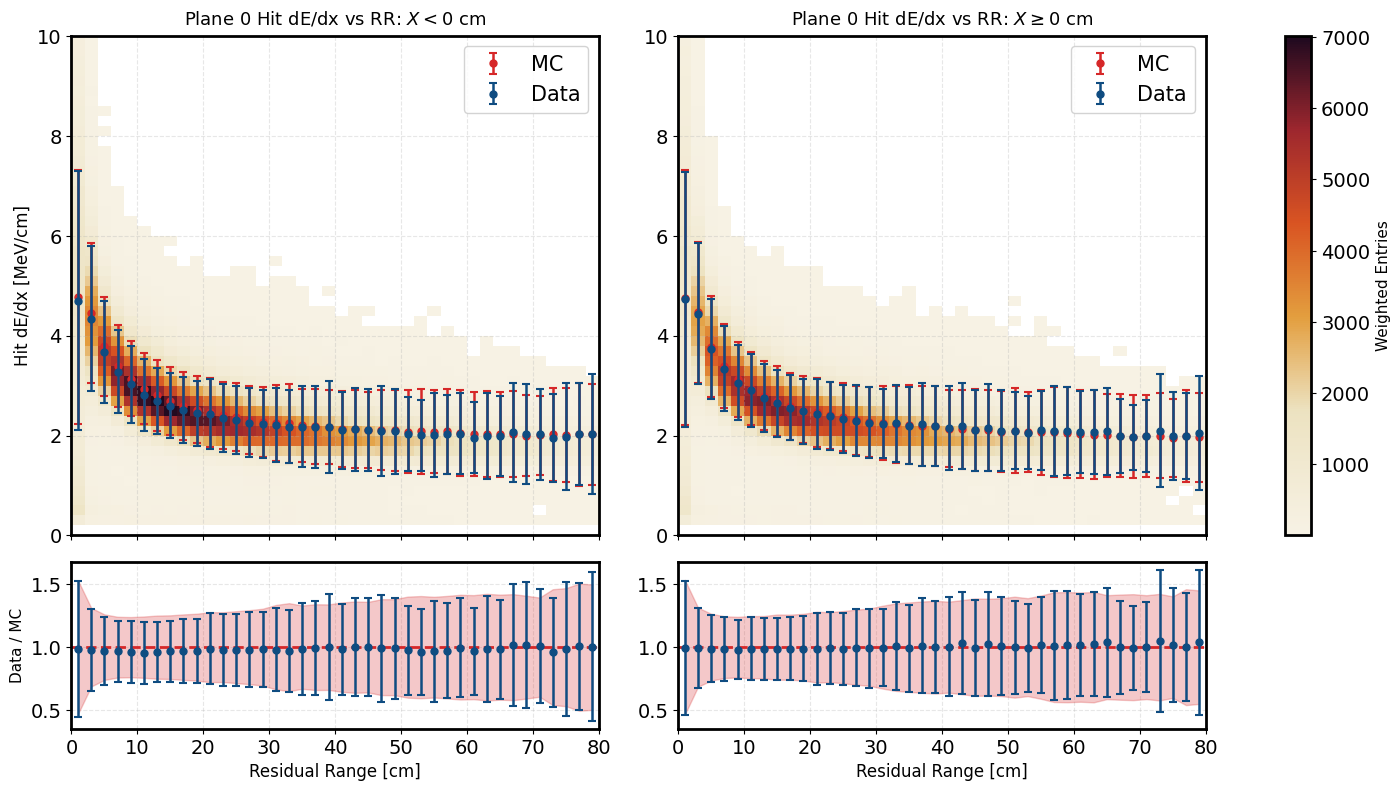

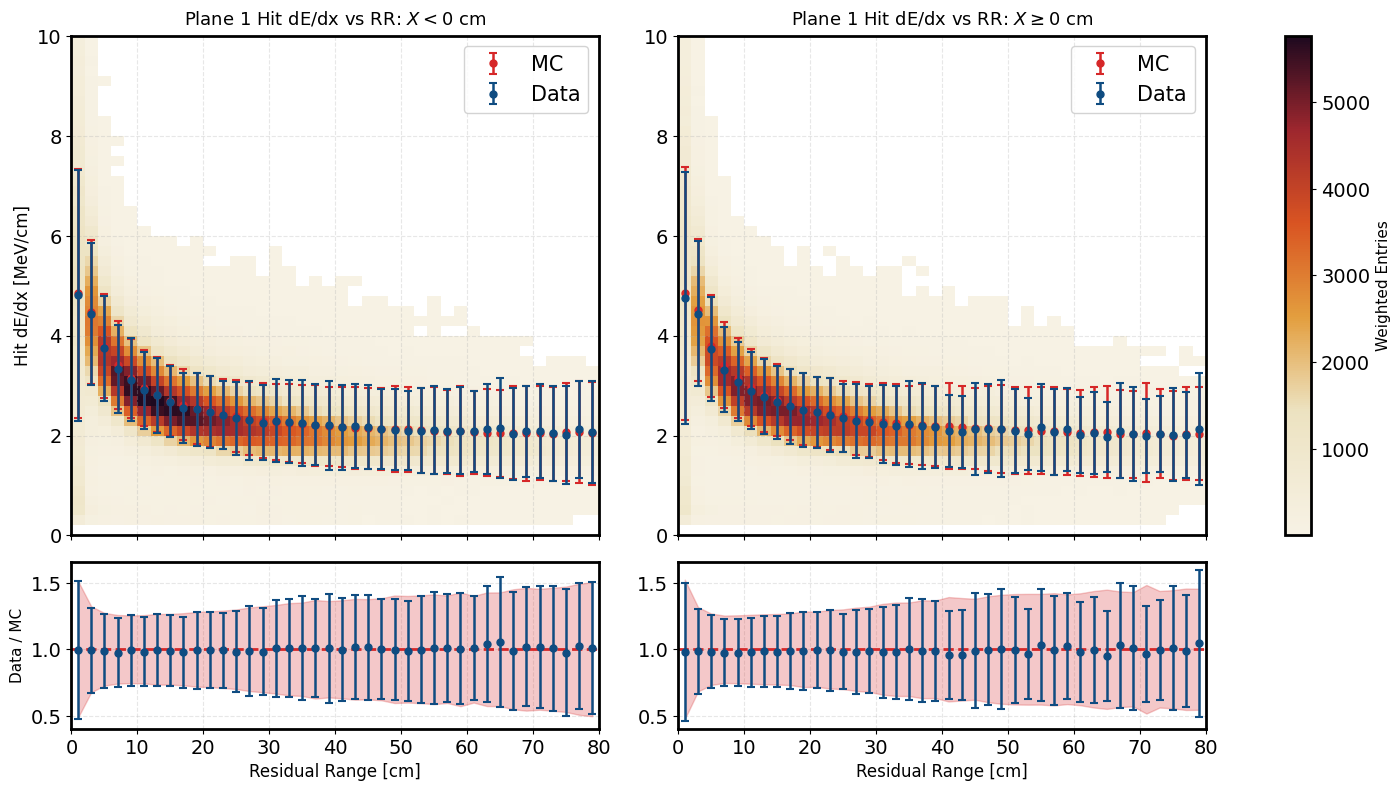

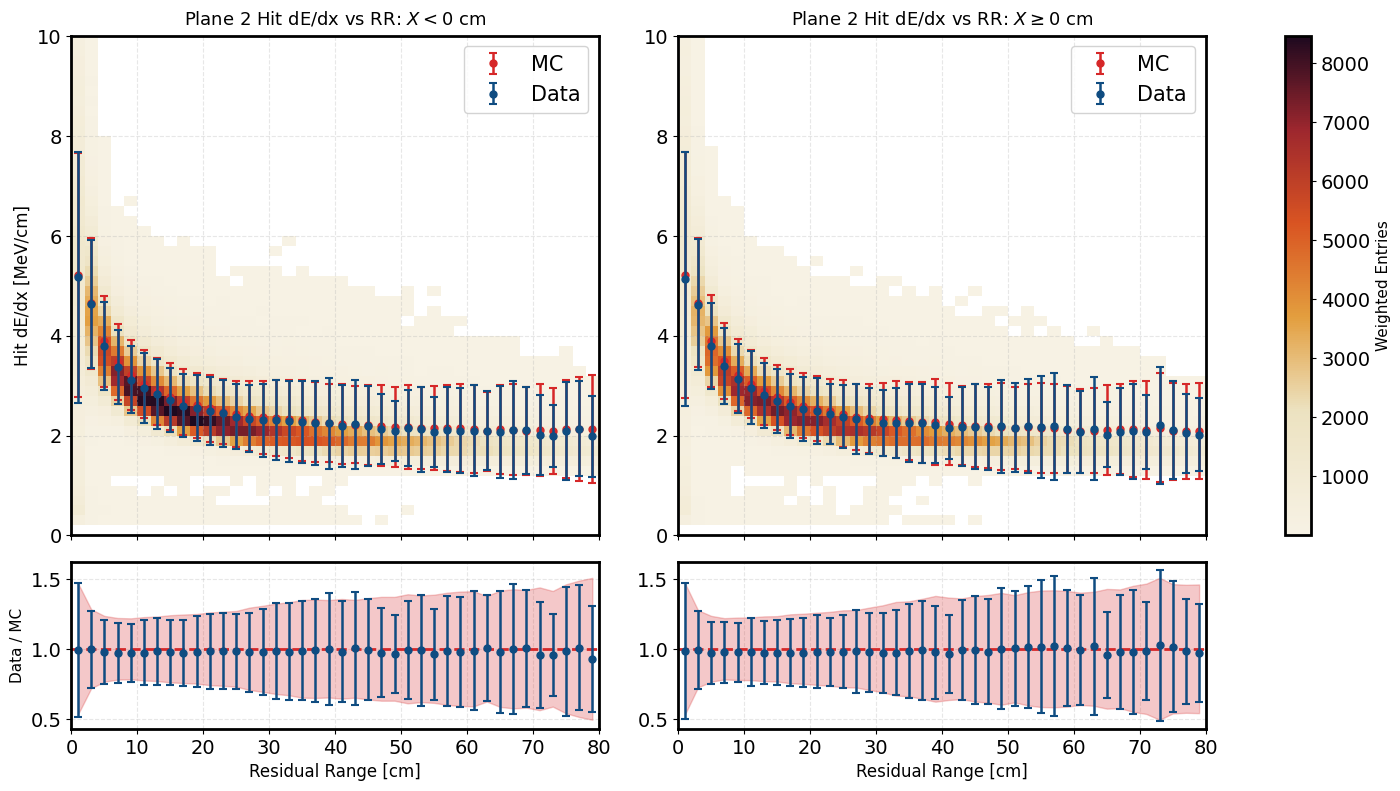

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Define bin ranges for Residual Range and dE/dx
rr_bins = np.linspace(0, 80, 41)      # Residual Range [cm]
dedx_bins = np.linspace(0, 10, 51)     # dE/dx [MeV/cm]

# MultiIndex weight tuple (or string/None depending on your DF structure)
mc_weight = ('slc', 'wgt', '', '', '', '') 

# Loop through planes 0, 1, and 2
for plane_name in ['0', '1', '2']:
    mc_hit_df = mc_bnb_hit_dfs.get(plane_name)
    data_hit_df = data_hit_dfs.get(plane_name)

    fig, axes = plot_split_tpc_2d_with_root_profile(
        mc_df=mc_hit_df,
        data_df=data_hit_df,
        x_col="rr",
        y_col="dedx",
        x_split_col="x",
        mc_weight_col=mc_weight,
        data_weight_col=None,  # Data typically unweighted
        bins_x=rr_bins,
        bins_y=dedx_bins,
        xlabel="Residual Range [cm]",
        ylabel="Hit dE/dx [MeV/cm]",
        title_prefix=f"Plane {plane_name} Hit dE/dx vs RR",
    )
    

plt.show()

In [10]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_dedx_by_rr_and_tpc(
    df: pd.DataFrame,
    data_df: pd.DataFrame = None,
    rr_range: tuple = (0.0, 1.0),
    dedx_col: str = "dedx",
    rr_col: str = "rr",
    x_col: str = "x",
    weight_col: str = None,
    data_weight_col: str = None,
    bins: np.ndarray = np.linspace(0.0, 10.0, 51),
    stacked: bool = False,
    density: bool = False,
    alpha: float = 0.3,
    linewidth: float = 1.8,
    marker_size: float = 5.0,
    title: str = None,
    ax_top: plt.Axes = None,
    ax_bot: plt.Axes = None,
):
    """Plots dE/dx distribution for MC (histograms) and Data (points) 

    with corresponding Data/MC ratios per X region (X > 0 and X <= 0).
    """

    # --- Helper: Apply identical filter and extract split arrays ---
    def _extract_and_split(data_frame, w_col):
        if data_frame is None or data_frame.empty:
            return None, None

        # Filter identically for both MC and Data
        mask = (
            data_frame[dedx_col].notna()
            & data_frame[rr_col].notna()
            & data_frame[x_col].notna()
            & (data_frame[rr_col] >= rr_range[0])
            & (data_frame[rr_col] < rr_range[1])
        )
        plot_df = data_frame[mask]
        if plot_df.empty:
            return None, None

        if w_col and w_col in plot_df.columns:
            w = plot_df[w_col].fillna(1.0)
        else:
            w = pd.Series(1.0, index=plot_df.index)

        # Categorization by X Position
        mask_pos = plot_df[x_col] > 0
        mask_neg = ~mask_pos

        grouped_data = [
            plot_df.loc[mask_pos, dedx_col],
            plot_df.loc[mask_neg, dedx_col],
        ]
        grouped_weights = [
            w[mask_pos],
            w[mask_neg],
        ]

        return grouped_data, grouped_weights

    # --- 1. Filter Data & MC Identically ---
    mc_data, mc_weights = _extract_and_split(df, weight_col)
    if mc_data is None:
        raise ValueError(
            f"No valid MC entries found for {rr_col} in range {rr_range}."
        )

    data_data, data_weights = _extract_and_split(data_df, data_weight_col)

    # --- 2. Identical Density Transformation (density=True) ---
    bin_width = bins[1] - bins[0]
    bin_centers = 0.5 * (bins[:-1] + bins[1:])

    def _apply_density_transform(grouped_w, is_stacked):
        if not density or grouped_w is None:
            return grouped_w

        if is_stacked:
            total_w = sum(w.sum() for w in grouped_w)
            if total_w > 0:
                scale = 1.0 / (total_w * bin_width)
                return [w * scale for w in grouped_w]
        else:
            normed = []
            for w in grouped_w:
                w_sum = w.sum()
                normed.append(
                    w / (w_sum * bin_width) if w_sum > 0 else w
                )
            return normed
        return grouped_w

    # Apply same density transform logic to both MC and Data
    mc_weights = _apply_density_transform(mc_weights, stacked)
    data_weights = _apply_density_transform(data_weights, False)

    colors = ["#1f77b4", "#d62728"]  # Blue ($X > 0$) & Red ($X \le 0$)
    labels = [r"MC: $X > 0$ cm", r"MC: $X \leq 0$ cm"]
    data_labels = [r"Data: $X > 0$ cm", r"Data: $X \leq 0$ cm"]

    # --- 3. Figure Layout Setup ---
    if ax_top is None or ax_bot is None:
        fig, (ax_top, ax_bot) = plt.subplots(
            2,
            1,
            figsize=(8, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08},
        )
    else:
        fig = ax_top.get_figure()

    # --- 4. Plot MC Histograms & Extract Individual MC Bins ---
    ax_top.hist(
        mc_data,
        bins=bins,
        weights=mc_weights,
        stacked=stacked,
        histtype="stepfilled",
        color=colors,
        alpha=alpha,
        label=labels,
    )

    ax_top.hist(
        mc_data,
        bins=bins,
        weights=mc_weights,
        stacked=stacked,
        histtype="step",
        color=colors,
        linewidth=linewidth,
    )

    # Compute unstacked individual MC bin counts for ratio division
    mc_unstacked_binned = []
    for idx in range(2):
        mc_c, _ = np.histogram(mc_data[idx], bins=bins, weights=mc_weights[idx])
        mc_unstacked_binned.append(mc_c)

    # --- 5. Plot Data Points & Calculate Specific Ratios ---
    if data_data is not None:
        for idx in range(2):  # idx 0: X > 0 (Blue), idx 1: X <= 0 (Red)
            d_vals = data_data[idx]
            d_w = data_weights[idx]

            # Compute Data binned values and errors
            data_c, _ = np.histogram(d_vals, bins=bins, weights=d_w)
            sum_w2, _ = np.histogram(d_vals, bins=bins, weights=d_w**2)
            data_err = np.sqrt(sum_w2)

            # Top plot: Data points
            valid_data = data_c > 0
            ax_top.errorbar(
                bin_centers[valid_data],
                data_c[valid_data],
                yerr=data_err[valid_data],
                fmt="o",
                color=colors[idx],
                ms=marker_size,
                elinewidth=linewidth,
                capsize=2,
                capthick=1.2,
                label=data_labels[idx],
                zorder=10 + idx,
            )

            # Bottom plot: Data / MC ratio per region
            # Data (X > 0) / MC (X > 0) AND Data (X <= 0) / MC (X <= 0)
            mc_c = mc_unstacked_binned[idx]

            with np.errstate(divide="ignore", invalid="ignore"):
                ratio = np.divide(data_c, mc_c)
                ratio_err = np.divide(data_err, mc_c)

            valid_ratio = np.isfinite(ratio) & (mc_c > 0)

            ax_bot.errorbar(
                bin_centers[valid_ratio],
                ratio[valid_ratio],
                yerr=ratio_err[valid_ratio],
                fmt="o",
                color=colors[idx],
                ms=marker_size,
                elinewidth=linewidth,
                capsize=2,
                capthick=1.2,
                zorder=10 + idx,
            )

    ax_bot.axhline(1.0, color="gray", linestyle="--", linewidth=1.5)

    # --- 6. Styling & Formatting ---
    ax_bot.set_xlabel(r"Hit $dE/dx$ [MeV/cm]", fontsize=13)

    if density:
        ax_top.set_ylabel("A.U.", fontsize=13)
    elif weight_col:
        ax_top.set_ylabel("Weighted Hits", fontsize=13)
    else:
        ax_top.set_ylabel("Hits", fontsize=13)

    ax_bot.set_ylabel("Data / MC", fontsize=11)

    if title is None:
        title = rf"Hit $dE/dx$ Distribution ({rr_range[0]} $\leq$ RR < {rr_range[1]} cm)"
    ax_top.set_title(title, fontsize=14, pad=10)

    ax_top.set_xlim(bins[0], bins[-1])
    ax_top.tick_params(axis="both", which="both", labelsize=11, direction="in")
    ax_bot.tick_params(axis="both", which="both", labelsize=11, direction="in")

    ax_top.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
    ax_bot.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

    ax_top.legend(
        fontsize=12,
        frameon=True,
        framealpha=1.0,
        edgecolor="black",
        fancybox=False,
    )

    return fig, (ax_top, ax_bot)

Saved plot to: /exp/sbnd/data/users/lpelegri/TLEGraphs/PDFExtractionDataMC/dedx_comp_rr_3_4cm.png
Saved plot to: /exp/sbnd/data/users/lpelegri/TLEGraphs/PDFExtractionDataMC/dedx_comp_rr_6_7cm.png
Saved plot to: /exp/sbnd/data/users/lpelegri/TLEGraphs/PDFExtractionDataMC/dedx_comp_rr_15_16cm.png


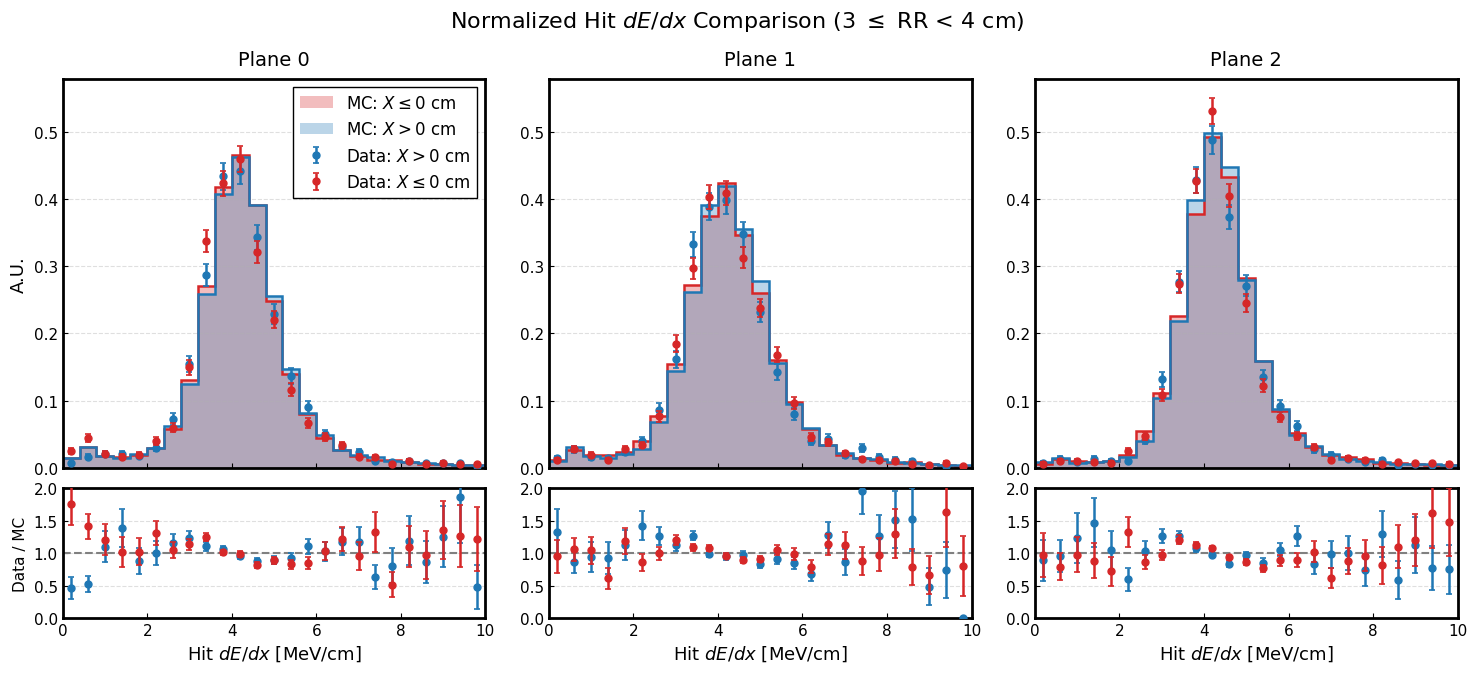

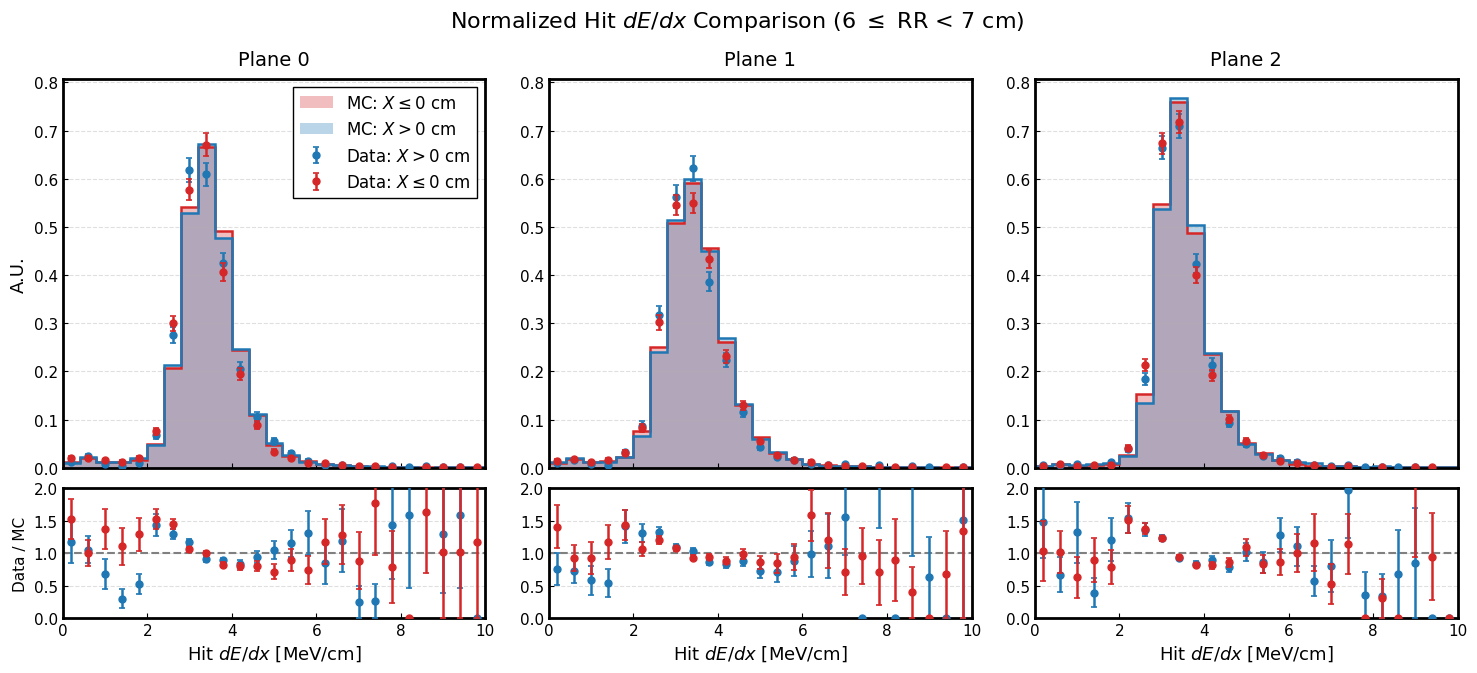

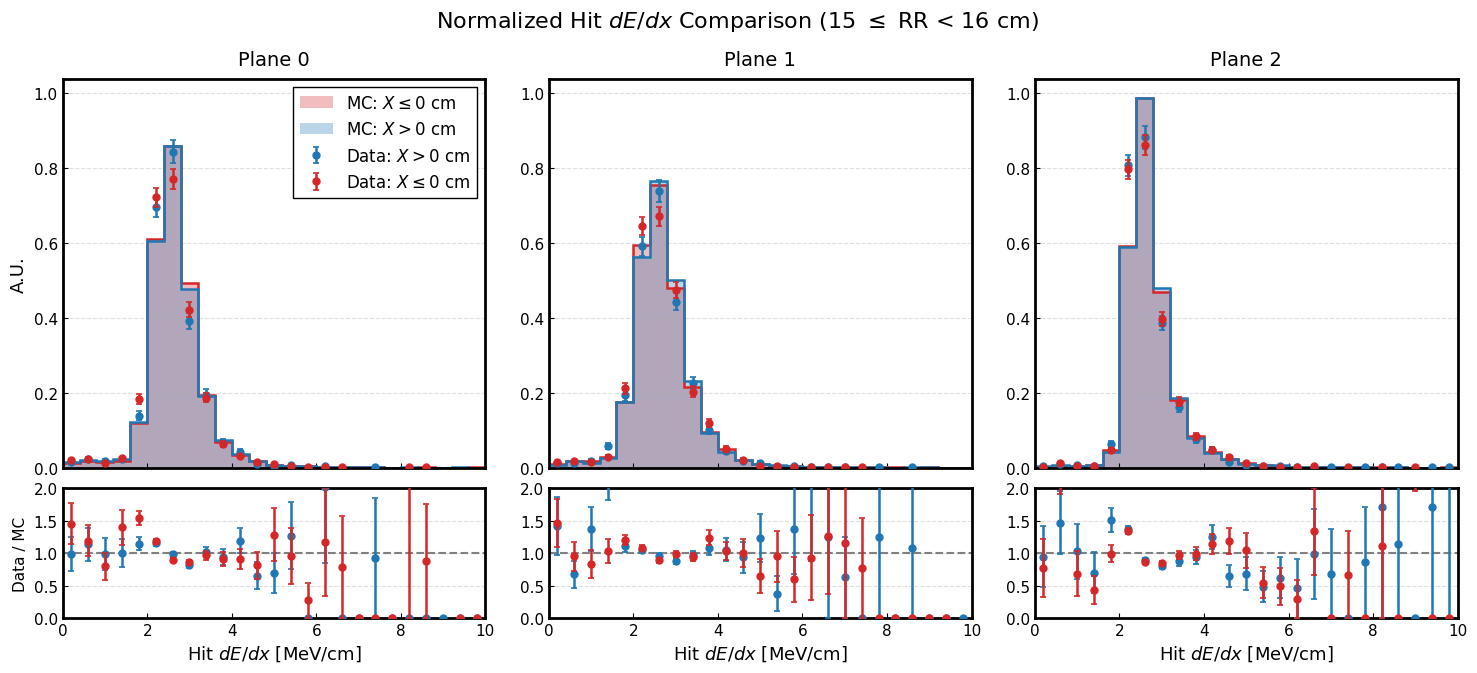

In [11]:
import os

output_dir = "/exp/sbnd/data/users/lpelegri/TLEGraphs/PDFExtractionDataMC"
os.makedirs(output_dir, exist_ok=True)


mc_hit_dfs = [mc_bnb_hit0_df, mc_bnb_hit1_df, mc_bnb_hit2_df]
data_hit_dfs = [
    data_hit0_df,
    data_hit1_df,
    data_hit2_df,
]  # Optional: Set to [None, None, None] if no Data available

rr_ranges = [(3, 4), (6, 7), (15, 16)]
x_ranges = [(0, 50), (50, 100), (100, 150), (150, 200)]

n_planes = 3

# Dictionary to hold everything
results_by_xrange = {}
figs_by_rr = {}  # figures for this x-range, keyed by rr_range

for rr_min, rr_max in rr_ranges:
    fig = plt.figure(figsize=(18, 7))
    gs = gridspec.GridSpec(
        2,
        n_planes,
        height_ratios=[3, 1],
        hspace=0.08,
        wspace=0.15,
    )
    top_axes = []
    bot_axes = []
    # Create top and bottom axes per plane
    for plane_idx in range(n_planes):
        ax_top = fig.add_subplot(gs[0, plane_idx])
        ax_bot = fig.add_subplot(
            gs[1, plane_idx],
            sharex=ax_top,
            sharey=bot_axes[0] if plane_idx > 0 else None,
        )
        top_axes.append(ax_top)
        bot_axes.append(ax_bot)

    max_y_value = 0.0  # Track global maximum height for top plots
    for plane_idx, (mc_df_plane, data_df_plane) in enumerate(
        zip(mc_hit_dfs, data_hit_dfs)
    ):
        ax_t = top_axes[plane_idx]
        ax_b = bot_axes[plane_idx]
        try:
            plot_dedx_by_rr_and_tpc(
                df=mc_df_plane,
                data_df=data_df_plane,
                rr_range=(rr_min, rr_max),
                dedx_col="dedx",
                rr_col="rr",
                x_col="x",
                weight_col=None,
                bins=np.linspace(0.0, 10.0, 26),
                stacked=False,
                density=True,
                title=f"Plane {plane_idx}",
                ax_top=ax_t,
                ax_bot=ax_b,
            )
            # Record max y for top plot alignment
            current_max = ax_t.get_ylim()[1] / 1.15
            if current_max > max_y_value:
                max_y_value = current_max
        except ValueError:
            ax_t.set_title(f"Plane {plane_idx}: No Data", fontsize=14, pad=10)
            ax_b.set_visible(False)
            continue

        # Hide redundant y-axis labels and legends on non-leftmost panels
        if plane_idx > 0:
            ax_t.set_ylabel("")
            ax_b.set_ylabel("")
            plt.setp(ax_t.get_yticklabels(), visible=True)
            plt.setp(ax_b.get_yticklabels(), visible=True)
            legend = ax_t.get_legend()
            if legend:
                legend.remove()

        # Hide top x-axis tick labels (sharex with ratio)
        plt.setp(ax_t.get_xticklabels(), visible=False)

    # Synchronize Y-limits across all top plots
    if max_y_value > 0:
        for ax_t in top_axes:
            ax_t.set_ylim(0, max_y_value * 1.15)

    # Synchronize Y-limits for bottom ratio plots (0.0 to 2.0 default)
    for ax_b in bot_axes:
        ax_b.set_ylim(0.0, 2.0)

    fig.suptitle(
        rf"Normalized Hit $dE/dx$ Comparison ({rr_min} $\leq$ RR < {rr_max} cm)",
        fontsize=16,
        y=0.98,
    )

    # --- SAVE FIGURE ---
    filename = f"dedx_comp_rr_{rr_min}_{rr_max}cm.png"
    filepath = os.path.join(output_dir, filename)

    fig.savefig(filepath, dpi=300, bbox_inches="tight")
    print(f"Saved plot to: {filepath}")

    figs_by_rr[(rr_min, rr_max)] = fig

In [12]:
hfit = load_physics_classes()

Done creating splines for particle with pdgcode 13
Done creating splines for particle with pdgcode 211
Done creating splines for particle with pdgcode 321
Done creating splines for particle with pdgcode 2212


Info in <TUnixSystem::ACLiC>: creating shared library /home/lpelegri/cafpyana/analysis_village/cc1pi/TLExtensionMethod/PhysdEdx_cpp.so
Info in <TUnixSystem::ACLiC>: creating shared library /home/lpelegri/cafpyana/analysis_village/cc1pi/TLExtensionMethod/Hypfit_cpp.so


In [13]:
pdg = 13
particle = "muon"
if "pion" in bnb_path:
    pdg = 211
    particle = "pion"

# 2. Analyze Data
data_results, data_sigma_fit_params,  data_shift_fit_params= analyze_theoretical(data_hit_dfs,hfit, pdg,  particle=particle)

# 3. Analyze MC
mc_results, mc_sigma_fit_params,  mc_shift_fit_params = analyze_theoretical(mc_hit_dfs,hfit, pdg,  particle=particle)

[theoretical] Plane 0, TPC 0
[theoretical] Plane 0, TPC 1
[theoretical] Plane 0, TPC combined
[theoretical] Plane 1, TPC 0
[theoretical] Plane 1, TPC 1
[theoretical] Plane 1, TPC combined
[theoretical] Plane 2, TPC 0
[theoretical] Plane 2, TPC 1
[theoretical] Plane 2, TPC combined
[theoretical] Plane 0, TPC 0
[theoretical] Plane 0, TPC 1
[theoretical] Plane 0, TPC combined
[theoretical] Plane 1, TPC 0
[theoretical] Plane 1, TPC 1
[theoretical] Plane 1, TPC combined
[theoretical] Plane 2, TPC 0
[theoretical] Plane 2, TPC 1
[theoretical] Plane 2, TPC combined


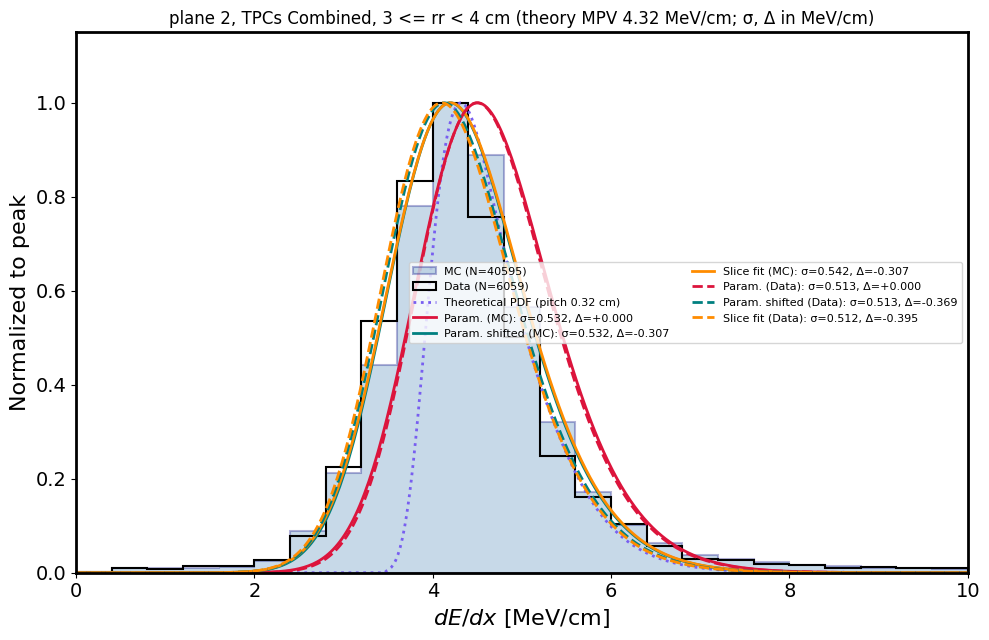

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Relies on functions from langau_rr_fit.py -- the same ones analyze_theoretical
# uses, so the curves are built exactly the way the fit built them:
#   build_theoretical_pdf, build_pdf_grid, convolved_theoretical_pdf,
#   robust_max_x_py, power_law, exp_decay_plateau

SAMPLE_STYLES = {
    "MC": dict(
        histtype="stepfilled",
        alpha=0.3,
        hist_color="steelblue",
        hist_edgecolor="navy",
        curve_ls="-",
    ),
    "Data": dict(
        histtype="step",
        alpha=1.0,
        hist_color="black",
        hist_edgecolor="black",
        curve_ls="--",
    ),
}

# One color per model; line style per sample (from SAMPLE_STYLES)
MODEL_COLORS = {
    "param": "crimson",          # parametrized sigma, no shift
    "param_shifted": "teal",     # parametrized sigma and shift
    "slice": "darkorange",       # this slice's own fitted sigma and shift
}
THEORY_COLOR = "#785EF0"  # colorblind-friendly purple


def _unit_peak(y):
    """Guard against NaN/inf and scale y so its maximum equals 1."""
    y = np.nan_to_num(np.asarray(y, dtype=float), nan=0.0, posinf=0.0, neginf=0.0)
    peak = y.max() if len(y) else 0.0
    return y / peak if peak > 0 else y


def _slice_row(results, plane, tpc, rr_center, tol=1e-6):
    """Return the analyze_theoretical row for this slice, or None if the slice
    was dropped by the fit selection or doesn't line up with the fit's slices."""
    res = results.get((plane, tpc))
    if res is None or len(res) == 0:
        return None
    match = res[np.abs(res["rr_center"] - rr_center) < tol]
    return match.iloc[0] if len(match) else None


def _draw_hist(ax, df, name, style, tpc, rr_min, rr_max, max_pitch,
               dedx_col, xmin, xmax, nbins):
    """Histogram of one sample's slice, scaled so its tallest bin equals 1.
    Returns its peak height (1, or 0 if empty)."""
    sl = df if tpc == -1 else df[df["tpc"] == tpc]
    sel = (sl["rr"] >= rr_min) & (sl["rr"] < rr_max)
    if max_pitch is not None:
        sel &= sl["pitch"] <= max_pitch
    sl = sl[sel]

    values = sl[dedx_col].dropna().to_numpy()
    counts, _ = np.histogram(values, bins=nbins, range=(xmin, xmax))
    if counts.max() == 0:
        print(f"  [warn] {name}: no {dedx_col} entries in [{xmin:g}, {xmax:g}] MeV/cm")
        return 0.0

    ax.hist(
        values,
        bins=nbins,
        range=(xmin, xmax),
        weights=np.full(len(values), 1.0 / counts.max()),
        histtype=style["histtype"],
        alpha=style["alpha"],
        color=style["hist_color"],
        edgecolor=style["hist_edgecolor"],
        lw=1.5,
        label=f"{name} (N={len(sl)})",
    )
    return 1.0


def _draw_model_curves(ax, name, style, x_eval, grid, mpv_theory, rr_center,
                       plane, tpc, results, sigma_fit_params, shift_fit_params,
                       show_slice_fit, show_unshifted):
    """Python-side convolution curves for one sample. Returns the largest y drawn."""
    x_grid, pdf_vals, dx = grid
    y_max = 0.0

    def draw(sigma, shift, label, color):
        y = convolved_theoretical_pdf(x_eval, sigma, shift, 1.0, x_grid, pdf_vals, dx)
        y = _unit_peak(y)
        ax.plot(
            x_eval,
            y,
            color=color,
            linestyle=style["curve_ls"],
            lw=2.0,
            label=f"{label} ({name}): σ={sigma:.3f}, Δ={shift:+.3f}",
        )
        return y.max()

    # Parametrized curves: sigma from the power law in MPV, shift from the
    # exponential decay in residual range -- same inputs as get_conv_function_map
    popt_sig = sigma_fit_params.get((plane, tpc), (None, None))[0]
    popt_shf = shift_fit_params.get((plane, tpc), (None, None))[0]

    if popt_sig is None:
        print(f"  [warn] {name}: no sigma fit for plane {plane}, tpc {tpc}")
    else:
        sigma = float(power_law(mpv_theory, *popt_sig))
        if show_unshifted:
            y_max = max(y_max, draw(sigma, 0.0, "Param.", MODEL_COLORS["param"]))
        if popt_shf is None:
            print(f"  [warn] {name}: no shift fit for plane {plane}, tpc {tpc}")
        else:
            shift = float(exp_decay_plateau(rr_center, *popt_shf))
            y_max = max(
                y_max,
                draw(sigma, shift, "Param. shifted", MODEL_COLORS["param_shifted"]),
            )

    # This slice's own fit result, before any parametrization
    if show_slice_fit:
        row = _slice_row(results, plane, tpc, rr_center)
        if row is None:
            print(
                f"  [info] {name}: no per-slice fit at rr={rr_center:g} cm "
                f"(dropped by the fit selection, or slice not aligned with the fit's 1 cm slices)"
            )
        else:
            y_max = max(
                y_max,
                draw(float(row["gsigma"]), float(row["shift"]), "Slice fit",
                     MODEL_COLORS["slice"]),
            )

    return y_max


def plot_slice_python_convolution(
    plane,
    tpc,
    rr_min,
    rr_max,
    hfit,
    pdg,
    data_hit_dfs,
    data_results,
    data_sigma_fit_params,
    data_shift_fit_params,
    mc_hit_dfs=None,
    mc_results=None,
    mc_sigma_fit_params=None,
    mc_shift_fit_params=None,
    pitch=0.32,
    mass=None,
    dedx_col="dedx",
    nbins=25,
    x_limits=(0.0, 10.0),
    max_pitch=2.0,
    show_theory=True,
    show_slice_fit=True,
    show_unshifted=True,
):
    """Slice diagnostic with the convolution done in Python from the
    analyze_theoretical outputs, instead of the C++ TF1 maps.

    Data is always drawn; MC is drawn only if all four mc_* inputs are given.
    hit_dfs are lists indexed by plane, e.g. [hit0_df, hit1_df, hit2_df].
    Histograms and curves are each scaled so their maximum equals 1."""
    xmin, xmax = x_limits
    rr_center = 0.5 * (rr_min + rr_max)

    # Theoretical PDF built exactly as in fit_rr_slices_theoretical
    pdf = build_theoretical_pdf(hfit, pdg, rr_center, pitch, mass=mass)
    mpv_theory = robust_max_x_py(pdf, 0.0, 10.0, 2000)
    grid = build_pdf_grid(pdf)
    x_eval = np.linspace(xmin, xmax, 400)

    samples = [("Data", data_hit_dfs, data_results,
                data_sigma_fit_params, data_shift_fit_params)]
    mc_inputs = (mc_hit_dfs, mc_results, mc_sigma_fit_params, mc_shift_fit_params)
    if all(v is not None for v in mc_inputs):
        samples.insert(0, ("MC", *mc_inputs))
    elif any(v is not None for v in mc_inputs):
        print("  [warn] incomplete MC inputs; drawing data only")

    fig, ax = plt.subplots(figsize=(10, 6.5))
    y_max = 0.0

    # Histograms first, so the curves are drawn on top
    for name, hit_dfs, _, _, _ in samples:
        y_max = max(
            y_max,
            _draw_hist(ax, hit_dfs[plane], name, SAMPLE_STYLES[name], tpc,
                       rr_min, rr_max, max_pitch, dedx_col, xmin, xmax, nbins),
        )

    # Unsmeared theory is identical for both samples (same pdg, rr, and pitch)
    if show_theory:
        y_theo = _unit_peak([pdf.Eval(xv) for xv in x_eval])
        ax.plot(x_eval, y_theo, color=THEORY_COLOR, linestyle=":", lw=2.0,
                label=f"Theoretical PDF (pitch {pitch:g} cm)")
        y_max = max(y_max, y_theo.max())

    for name, _, results, sig_params, shf_params in samples:
        y_max = max(
            y_max,
            _draw_model_curves(ax, name, SAMPLE_STYLES[name], x_eval, grid,
                               mpv_theory, rr_center, plane, tpc, results,
                               sig_params, shf_params, show_slice_fit,
                               show_unshifted),
        )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(0, y_max * 1.15 if y_max > 0 else 1.0)
    ax.set_xlabel(r"$dE/dx$ [MeV/cm]")
    ax.set_ylabel("Normalized to peak")
    ax.legend(fontsize=8, ncol=2)

    tpc_str = "TPCs Combined" if tpc == -1 else f"TPC {tpc}"
    ax.set_title(
        f"plane {plane}, {tpc_str}, {rr_min:g} <= rr < {rr_max:g} cm "
        f"(theory MPV {mpv_theory:.2f} MeV/cm; σ, Δ in MeV/cm)",
        fontsize=12,
    )
    fig.tight_layout()
    plt.show()
    return fig


# ---------------------------------------------------------------------------
# Example usage
# ---------------------------------------------------------------------------
# data_hit_dfs = [data_hit0_df, data_hit1_df, data_hit2_df]
# mc_hit_dfs = [mc_bnb_hit0_df, mc_bnb_hit1_df, mc_bnb_hit2_df]
# pdg = 211 if particle == "pion" else 13
#
# fig = plot_slice_python_convolution(
#     plane=2, tpc=-1, rr_min=15, rr_max=16,
#     hfit=hfit, pdg=pdg,
#     data_hit_dfs=data_hit_dfs,
#     data_results=data_results,
#     data_sigma_fit_params=data_sigma_fit_params,
#     data_shift_fit_params=data_shift_fit_params,
#     mc_hit_dfs=mc_hit_dfs,                      # optional
#     mc_results=mc_results,                      # optional
#     mc_sigma_fit_params=mc_sigma_fit_params,    # optional
#     mc_shift_fit_params=mc_shift_fit_params,    # optional
# )

data_hit_dfs = [data_hit0_df, data_hit1_df, data_hit2_df]
mc_hit_dfs = [mc_bnb_hit0_df, mc_bnb_hit1_df, mc_bnb_hit2_df]
pdg = 211 if particle == "pion" else 13

fig = plot_slice_python_convolution(
    plane=2, tpc=-1, rr_min=3, rr_max=4,
    hfit=hfit, pdg=pdg,
    data_hit_dfs=data_hit_dfs,
    data_results=data_results,
    data_sigma_fit_params=data_sigma_fit_params,
    data_shift_fit_params=data_shift_fit_params,
    mc_hit_dfs=mc_hit_dfs,                      # optional
    mc_results=mc_results,                      # optional
    mc_sigma_fit_params=mc_sigma_fit_params,    # optional
    mc_shift_fit_params=mc_shift_fit_params,    # optional
)

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Define default TPC colors and labels
TPC_COLORS = {
    0: "#1f77b4",   # Blue for TPC 0
    1: "#ff7f0e",   # Orange for TPC 1
    -1: "#2ca02c",  # Green for Combined
}

TPC_LABELS = {
    0: "TPC 0",
    1: "TPC 1",
    -1: "Combined",
}


def plot_all_planes(
    data_results,
    data_params,
    mc_results,
    mc_params,
    particle="muon",
    out_prefix="langau_rr",
    show_data_fits=True,
    show_mc_fits=True,
):
    """3 panels (Plane 0, Plane 1, Plane 2), with TPC curves overlaid (colored by TPC)."""
    tpc_list = [0, 1, -1]

    # Subplots arranged by Plane (0, 1, 2)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, layout="constrained")

    for plane in range(3):
        ax = axes[plane]

        for tpc in tpc_list:
            color = TPC_COLORS[tpc]
            tpc_lbl = TPC_LABELS[tpc]

            if show_data_fits:
                res_data = data_results.get((plane, tpc))
                popt_data, _ = data_params.get((plane, tpc), (None, None))
                if (
                    res_data is not None
                    and len(res_data)
                    and popt_data is not None
                ):
                    xs = np.linspace(
                        res_data["mpv_x"].min(), res_data["mpv_x"].max(), 200
                    )
                    ax.plot(
                        xs,
                        power_law(xs, *popt_data),
                        "-",
                        color=color,
                        linewidth=2.0,
                        label=f"Data {tpc_lbl}",
                    )

            if show_mc_fits:
                res_mc = mc_results.get((plane, tpc))
                popt_mc, _ = mc_params.get((plane, tpc), (None, None))
                if res_mc is not None and len(res_mc) and popt_mc is not None:
                    xs = np.linspace(
                        res_mc["mpv_x"].min(), res_mc["mpv_x"].max(), 200
                    )
                    ax.plot(
                        xs,
                        power_law(xs, *popt_mc),
                        "--",
                        color=color,
                        linewidth=2.0,
                        label=f"MC {tpc_lbl}",
                    )

        ax.set_title(f"Plane {plane}", fontsize=17, pad=10)
        ax.set_xlabel("MPV [MeV/cm]", fontsize=16)
        if plane == 0:
            ax.set_ylabel(r"$\sigma_G$ [MeV/cm]", fontsize=16)

        ax.tick_params(axis="both", labelsize=14)
        ax.legend(fontsize=14, loc="upper left", framealpha=0.9)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.set_box_aspect(1)

    fig.savefig(f"{out_prefix}_all_planes_data_mc.pdf", bbox_inches="tight")
    plt.show()


def plot_by_plane(
    data_results,
    data_params,
    mc_results,
    mc_params,
    particle="muon",
    out_prefix="langau_rr",
    show_data_points=False,
    show_mc_points=False,
    show_data_fits=True,
    show_mc_fits=True,
):
    """Grid of (Plane row) x (TPC col) panels."""
    planes = [0, 1, 2]
    tpcs = [1, 0, -1]
    tpc_titles = {
        1: r"$X > 0$ (TPC 1)",
        0: r"$X < 0$ (TPC 0)",
        -1: "Both TPCs Combined",
    }

    n_rows = len(planes)
    row_height = 5.0
    fixed_overhead = 0.8
    fig_height = row_height * n_rows + fixed_overhead

    fig, axes = plt.subplots(
        n_rows, 3, figsize=(16, fig_height), sharex=True, sharey="row", layout="constrained"
    )

    color_data = "#1f77b4"  # Blue
    color_mc = "#d62728"    # Red

    for row_idx, plane in enumerate(planes):
        for col_idx, tpc in enumerate(tpcs):
            ax = axes[row_idx, col_idx]

            res_data = data_results.get((plane, tpc))
            popt_data, _ = data_params.get((plane, tpc), (None, None))

            if res_data is not None and len(res_data):
                if show_data_points:
                    ax.errorbar(
                        res_data["mpv_x"],
                        res_data["gsigma"],
                        yerr=res_data["gsigma_err"],
                        fmt="o",
                        color=color_data,
                        ms=4,
                        capsize=2,
                        label="Data Points",
                    )
                if show_data_fits and popt_data is not None:
                    xs = np.linspace(
                        res_data["mpv_x"].min(), res_data["mpv_x"].max(), 200
                    )
                    ax.plot(
                        xs,
                        power_law(xs, *popt_data),
                        "-",
                        color=color_data,
                        linewidth=1.8,
                        label="Data Fit",
                    )

            res_mc = mc_results.get((plane, tpc))
            popt_mc, _ = mc_params.get((plane, tpc), (None, None))

            if res_mc is not None and len(res_mc):
                if show_mc_points:
                    ax.errorbar(
                        res_mc["mpv_x"],
                        res_mc["gsigma"],
                        yerr=res_mc["gsigma_err"],
                        fmt="s",
                        color=color_mc,
                        ms=3,
                        capsize=2,
                        label="MC Points",
                    )
                if show_mc_fits and popt_mc is not None:
                    xs = np.linspace(
                        res_mc["mpv_x"].min(), res_mc["mpv_x"].max(), 200
                    )
                    ax.plot(
                        xs,
                        power_law(xs, *popt_mc),
                        "--",
                        color=color_mc,
                        linewidth=1.8,
                        label="MC Fit",
                    )

            if row_idx == 0:
                ax.set_title(tpc_titles[tpc], fontsize=18, pad=10)
            if row_idx == n_rows - 1:
                ax.set_xlabel("MPV [MeV/cm]", fontsize=16)
            if col_idx == 0:
                ax.set_ylabel(
                    f"Plane {plane}\n" + r"$\sigma_G$ [MeV/cm]",
                    fontsize=16,
                )

            ax.tick_params(axis="both", labelsize=14)
            ax.legend(fontsize=14, loc="upper left", framealpha=0.9)
            ax.grid(True, linestyle=":", alpha=0.5)
            ax.set_box_aspect(1)

    fig.savefig(f"{out_prefix}_by_plane_data_mc.pdf", bbox_inches="tight")
    plt.show()


def plot_all_planes_shift_data_mc(
    data_results,
    data_shift_params,
    mc_results,
    mc_shift_params,
    particle="muon",
    out_prefix="langau_rr",
    show_data_fits=True,
    show_mc_fits=True,
):
    """3 panels (Plane 0, Plane 1, Plane 2), all 3 TPCs' shift-fit curves overlaid (colored by TPC)."""
    tpc_list = [0, 1, -1]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, layout="constrained")

    for plane in range(3):
        ax = axes[plane]

        for tpc in tpc_list:
            color = TPC_COLORS[tpc]
            tpc_lbl = TPC_LABELS[tpc]

            if show_data_fits:
                res_data = data_results.get((plane, tpc))
                popt_data, _ = data_shift_params.get((plane, tpc), (None, None))
                if (
                    res_data is not None
                    and len(res_data)
                    and popt_data is not None
                ):
                    xs = np.linspace(
                        res_data["rr_center"].min(), res_data["rr_center"].max(), 200
                    )
                    ax.plot(
                        xs,
                        eval_shift_fit(xs, popt_data),
                        "-",
                        color=color,
                        linewidth=2.0,
                        label=f"Data {tpc_lbl}",
                    )

            if show_mc_fits:
                res_mc = mc_results.get((plane, tpc))
                popt_mc, _ = mc_shift_params.get((plane, tpc), (None, None))
                if res_mc is not None and len(res_mc) and popt_mc is not None:
                    xs = np.linspace(
                        res_mc["rr_center"].min(), res_mc["rr_center"].max(), 200
                    )
                    ax.plot(
                        xs,
                        eval_shift_fit(xs, popt_mc),
                        "--",
                        color=color,
                        linewidth=2.0,
                        label=f"MC {tpc_lbl}",
                    )

        ax.set_title(f"Plane {plane}", fontsize=17, pad=10)
        ax.set_xlabel("Residual Range [cm]", fontsize=16)
        if plane == 0:
            ax.set_ylabel(r"Shift $\Delta$MPV [MeV/cm]", fontsize=16)

        ax.tick_params(axis="both", labelsize=14)
        ax.legend(fontsize=14, loc="lower right", framealpha=0.9)
        ax.grid(True, linestyle=":", alpha=0.6)
        ax.set_box_aspect(1)

    fig.savefig(f"{out_prefix}_all_planes_shift_data_mc.pdf", bbox_inches="tight")
    plt.show()


def plot_by_plane_shift_data_mc(
    data_results,
    data_shift_params,
    mc_results,
    mc_shift_params,
    particle="muon",
    out_prefix="langau_rr",
    show_data_points=False,
    show_mc_points=False,
    show_data_fits=True,
    show_mc_fits=True,
):
    """Grid of (Plane row) x (TPC col) shift panels, data vs MC overlaid."""
    planes = [0, 1, 2]
    tpcs = [1, 0, -1]
    tpc_titles = {
        1: r"$X > 0$ (TPC 1)",
        0: r"$X < 0$ (TPC 0)",
        -1: "Both TPCs Combined",
    }

    n_rows = len(planes)
    row_height = 5.0
    fixed_overhead = 0.8
    fig_height = row_height * n_rows + fixed_overhead

    fig, axes = plt.subplots(
        n_rows, 3, figsize=(16, fig_height), sharex=True, sharey="row", layout="constrained"
    )

    color_data = "#1f77b4"  # Blue
    color_mc = "#d62728"    # Red

    for row_idx, plane in enumerate(planes):
        for col_idx, tpc in enumerate(tpcs):
            ax = axes[row_idx, col_idx]

            res_data = data_results.get((plane, tpc))
            popt_data, _ = data_shift_params.get((plane, tpc), (None, None))

            if res_data is not None and len(res_data):
                if show_data_points:
                    ax.errorbar(
                        res_data["rr_center"],
                        res_data["shift"],
                        yerr=res_data["shift_err"],
                        fmt="o",
                        color=color_data,
                        ms=4,
                        capsize=2,
                        label="Data Points",
                    )
                if show_data_fits and popt_data is not None:
                    xs = np.linspace(
                        res_data["rr_center"].min(), res_data["rr_center"].max(), 200
                    )
                    ax.plot(
                        xs,
                        eval_shift_fit(xs, popt_data),
                        "-",
                        color=color_data,
                        linewidth=1.8,
                        label="Data Fit",
                    )

            res_mc = mc_results.get((plane, tpc))
            popt_mc, _ = mc_shift_params.get((plane, tpc), (None, None))

            if res_mc is not None and len(res_mc):
                if show_mc_points:
                    ax.errorbar(
                        res_mc["rr_center"],
                        res_mc["shift"],
                        yerr=res_mc["shift_err"],
                        fmt="s",
                        color=color_mc,
                        ms=3,
                        capsize=2,
                        label="MC Points",
                    )
                if show_mc_fits and popt_mc is not None:
                    xs = np.linspace(
                        res_mc["rr_center"].min(), res_mc["rr_center"].max(), 200
                    )
                    ax.plot(
                        xs,
                        eval_shift_fit(xs, popt_mc),
                        "--",
                        color=color_mc,
                        linewidth=1.8,
                        label="MC Fit",
                    )

            if row_idx == 0:
                ax.set_title(tpc_titles[tpc], fontsize=18, pad=10)
            if row_idx == n_rows - 1:
                ax.set_xlabel("Residual Range [cm]", fontsize=16)
            if col_idx == 0:
                ax.set_ylabel(
                    f"Plane {plane}\n" + r"Shift $\Delta$MPV [MeV/cm]",
                    fontsize=16,
                )

            ax.tick_params(axis="both", labelsize=14)
            ax.legend(fontsize=14, loc="lower right", framealpha=0.9)
            ax.grid(True, linestyle=":", alpha=0.5)
            ax.set_box_aspect(1)

    fig.savefig(f"{out_prefix}_by_plane_shift_data_mc.pdf", bbox_inches="tight")
    plt.show()

In [16]:

PLANE_COLORS = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

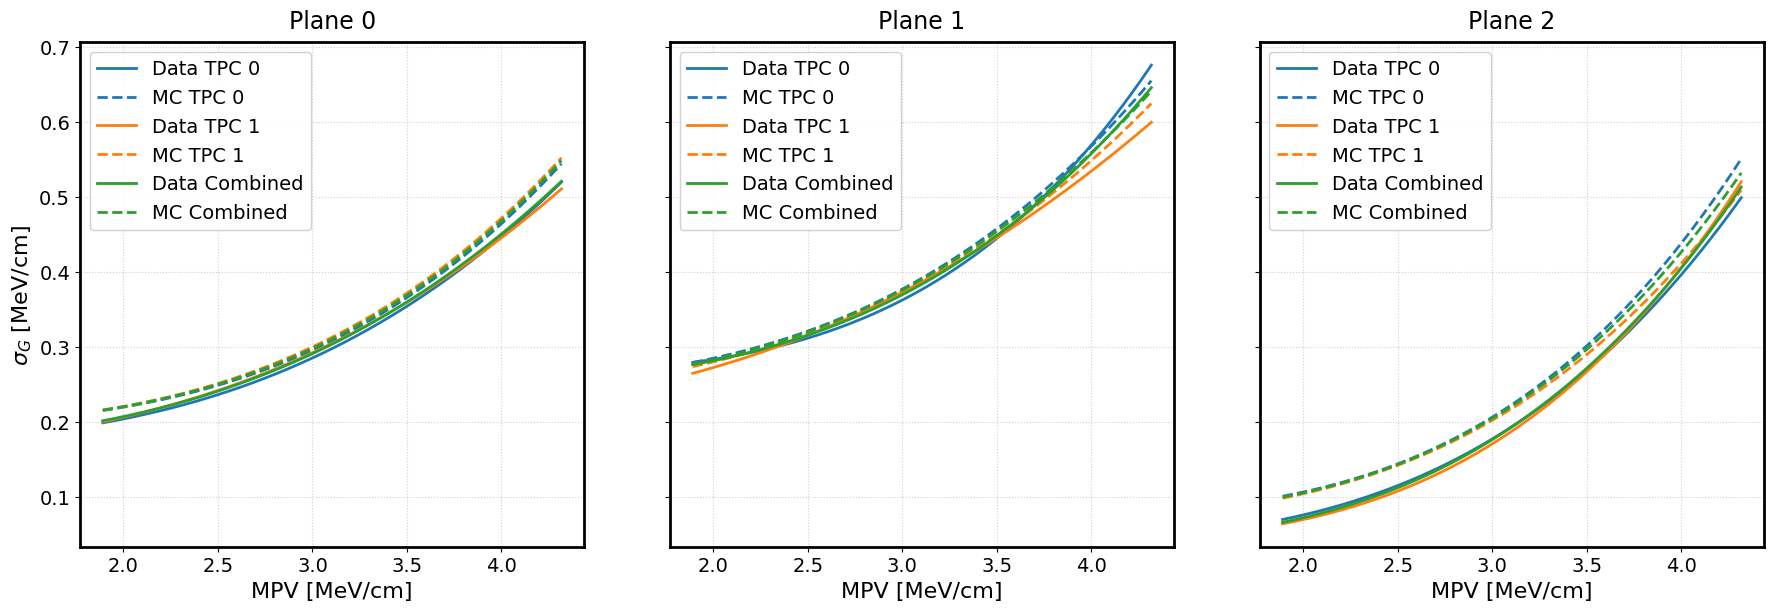

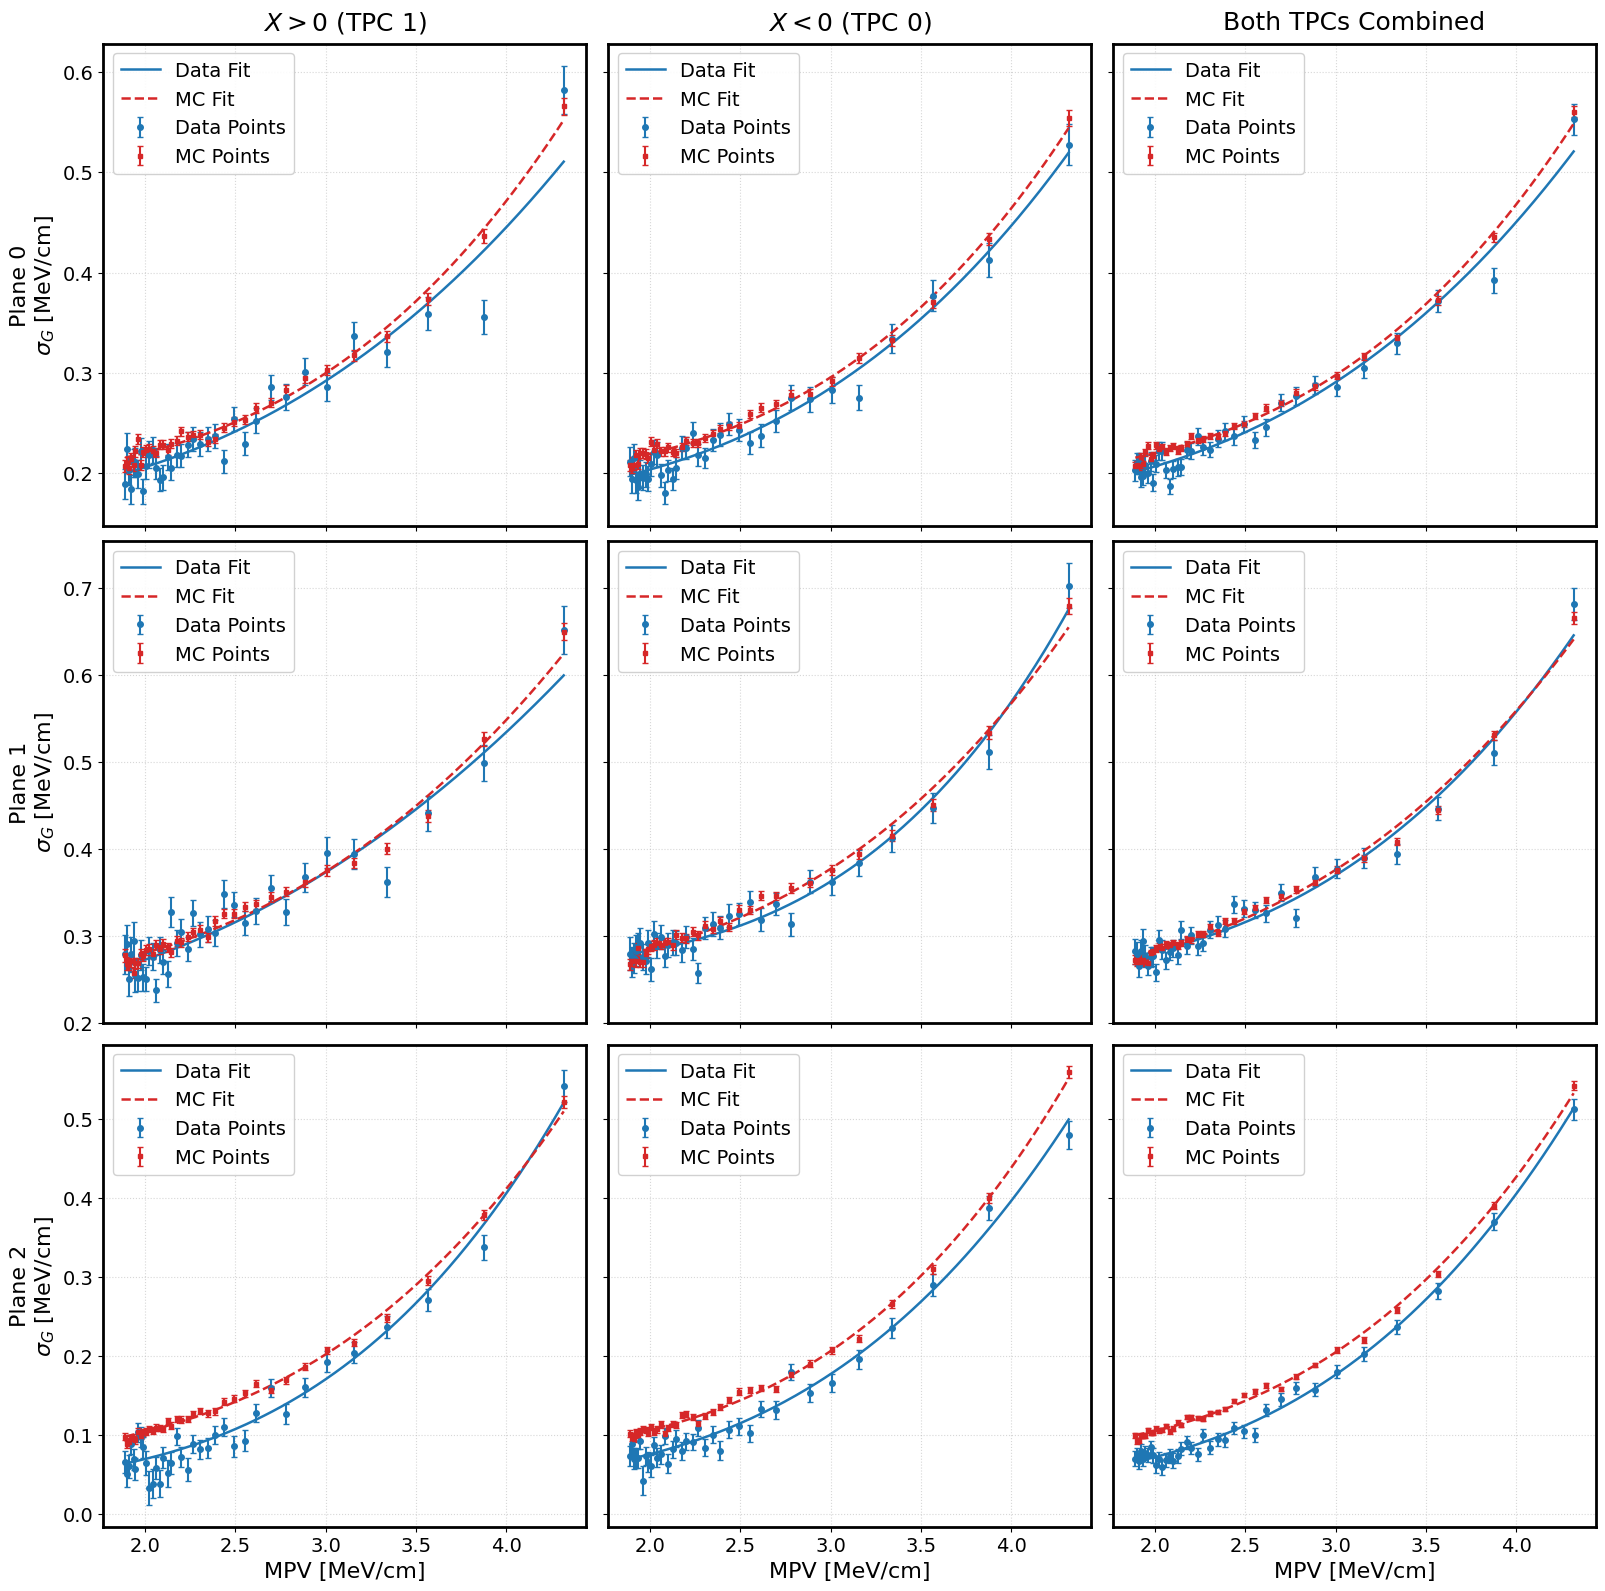

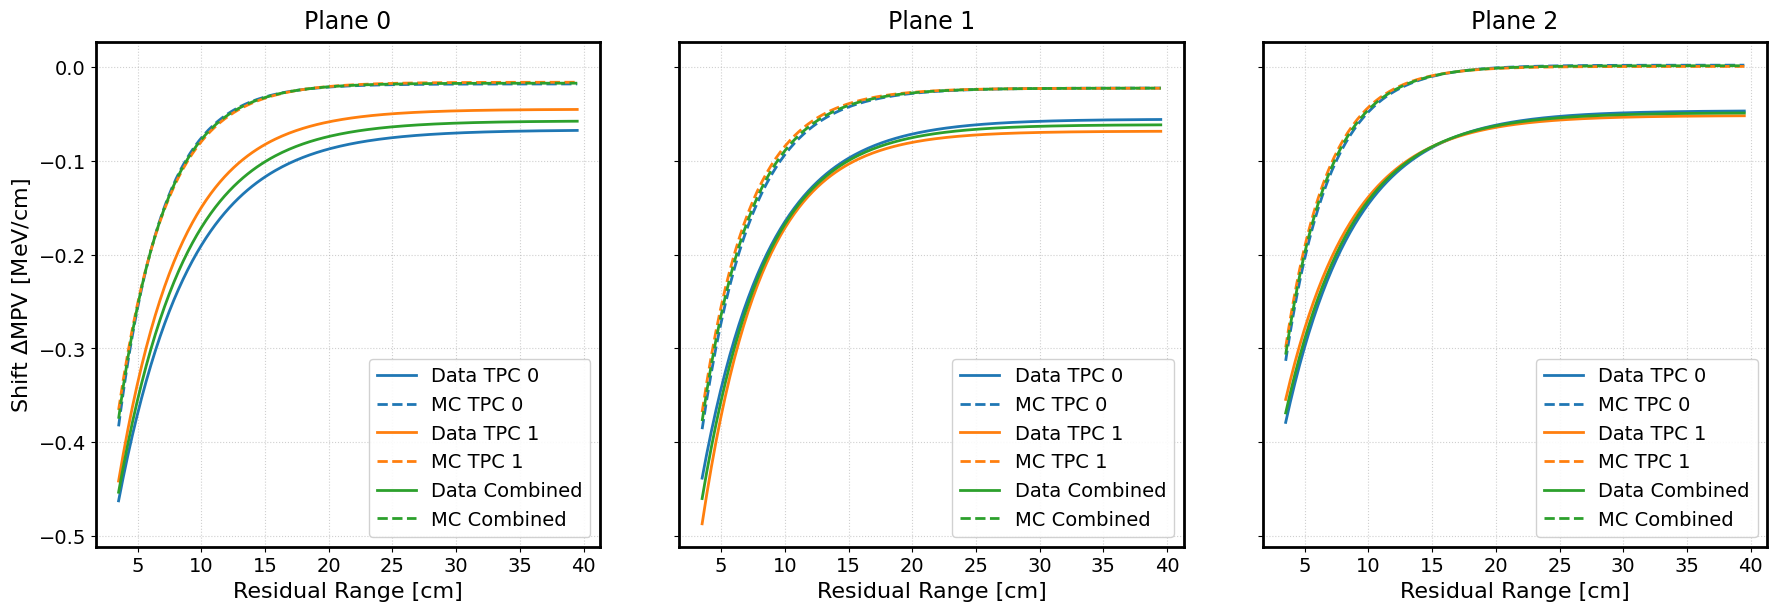

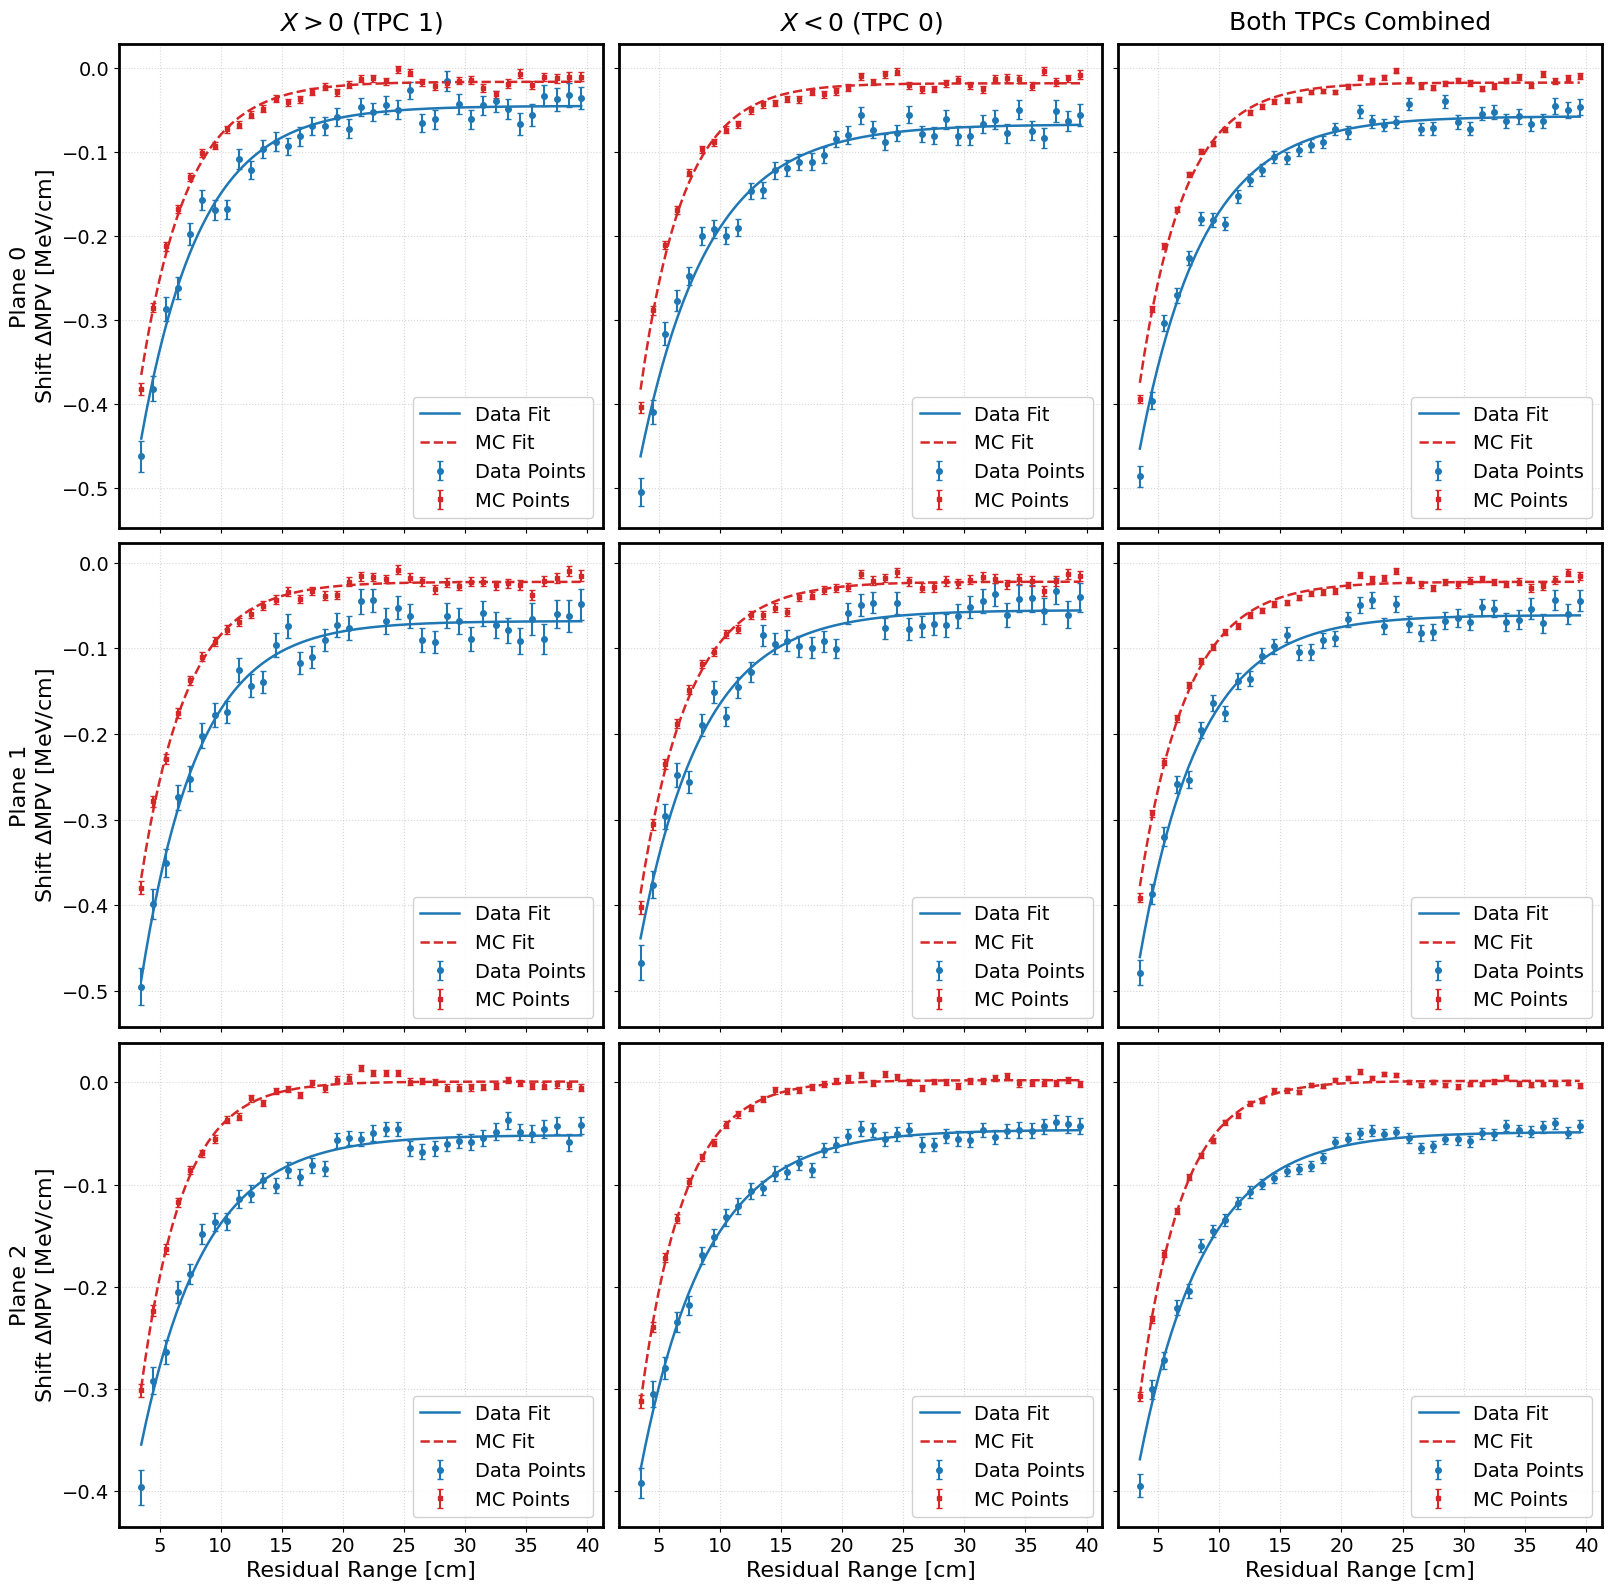

In [17]:
# 4. Generate Data vs. MC comparison plots

output_dir = "/exp/sbnd/data/users/lpelegri/TLEGraphs/PDFExtractionDataMC"
os.makedirs(output_dir, exist_ok=True)

plot_all_planes(
    data_results,
    data_sigma_fit_params,
    mc_results,
    mc_sigma_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
)

plot_by_plane(
    data_results,
    data_sigma_fit_params,
    mc_results,
    mc_sigma_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
    show_data_points=True,  # Set to True
    show_mc_points=True,    # Set to True
)

# 5. Generate Data vs. MC shift comparison plots
plot_all_planes_shift_data_mc(
    data_results,
    data_shift_fit_params,
    mc_results,
    mc_shift_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
)
plot_by_plane_shift_data_mc(
    data_results,
    data_shift_fit_params,
    mc_results,
    mc_shift_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
    show_data_points=True,  # Set to True
    show_mc_points=True,    # Set to True
)

In [18]:
import matplotlib.pyplot as plt
import numpy as np


def plot_data_vs_mc_fit(
    data_results,
    mc_results,
    mc_params,
    particle="muon",
    out_prefix="langau_rr",
    max_yerr=0.1,  # Added threshold for plotting
):
    # Always plot 3 rows: TPC 1, TPC 0, and Combined (-1)
    tpcs = [1, 0, -1]
    row_labels = [
        r"$X > 0$ (TPC 1)",
        r"$X < 0$ (TPC 0)",
        "Both TPCs Combined",
    ]

    n_rows = len(tpcs)
    row_height = 5.0  # per-row plotting height
    fixed_overhead = (
        0.8  # inches reserved for titles, labels, and tick margins
    )
    fig_height = row_height * n_rows + fixed_overhead

    fig, axes = plt.subplots(
        n_rows, 3, figsize=(16, fig_height), sharex=True, sharey="row"
    )

    color_data = "#1f77b4"  # Blue
    color_mc = "#d62728"  # Red

    for row_idx, tpc in enumerate(tpcs):
        for plane in range(3):
            ax = axes[row_idx, plane]

            raw_data = data_results.get((plane, tpc))
            res_mc = mc_results.get((plane, tpc))
            popt_mc, _ = mc_params.get((plane, tpc), (None, None))

            # Filter data points with gsigma_err <= max_yerr
            res_data = None
            if raw_data is not None and len(raw_data):
                mask = (
                    (raw_data["gsigma_err"] <= max_yerr)
                    & (raw_data["gsigma_err"] > 0)
                    & np.isfinite(raw_data["gsigma_err"])
                )
                res_data = raw_data[mask]

            # --- 1. Plot MC Fit Curve ---
            if popt_mc is not None and res_data is not None and len(res_data):
                x_min = res_data["mpv_x"].min()
                x_max = res_data["mpv_x"].max()
                xs = np.linspace(x_min, x_max, 200)

                label_mc = (
                    f"MC Fit"
                )
                ax.plot(
                    xs,
                    power_law(xs, *popt_mc),
                    "--",
                    color=color_mc,
                    linewidth=2.0,
                    label=label_mc,
                )

            # --- 2. Plot Filtered Data Points & Compute Chi2 / NDF ---
            if res_data is not None and len(res_data):
                ax.errorbar(
                    res_data["mpv_x"],
                    res_data["gsigma"],
                    yerr=res_data["gsigma_err"],
                    fmt="o",
                    color=color_data,
                    ms=4,
                    capsize=2,
                    label="Data Points",
                )

                if popt_mc is not None:
                    x_val = res_data["mpv_x"].to_numpy()
                    y_val = res_data["gsigma"].to_numpy()
                    yerr_val = res_data["gsigma_err"].to_numpy()

                    expected = power_law(x_val, *popt_mc)
                    residuals = (y_val - expected) / yerr_val
                    chi2 = np.sum(residuals**2)
                    ndf = len(x_val)
                    chi2_ndf = chi2 / ndf if ndf > 0 else np.nan

                    text_str = rf"$\chi^2/\mathrm{{NDF}} = {chi2:.2f}/{ndf} = {chi2_ndf:.2f}$"

                    # Bottom right corner text block
                    ax.text(
                        0.95,
                        0.08,
                        text_str,
                        transform=ax.transAxes,
                        fontsize=14,  # Increased +4 (was 10)
                        verticalalignment="bottom",
                        horizontalalignment="right",
                        bbox=dict(
                            boxstyle="round,pad=0.3",
                            facecolor="white",
                            alpha=0.85,
                            edgecolor="none",
                        ),
                    )

            # --- Formatting ---
            if row_idx == 0:
                ax.set_title(f"Plane {plane}", fontsize=18, pad=10)  # Increased +4 (was 14)
            if row_idx == n_rows - 1:
                ax.set_xlabel("MPV [MeV/cm]", fontsize=16)  # Increased +4 (was 12)
            if plane == 0:
                ax.set_ylabel(
                    f"{row_labels[row_idx]}\n" + r"$\sigma_G$ [MeV/cm]",
                    fontsize=16,  # Increased +4 (was 12)
                )

            ax.tick_params(axis="both", labelsize=14)  # Explicitly set tick labels +4
            ax.legend(fontsize=16, loc="upper left", framealpha=0.9)  # Increased +4 (was 10)
            ax.grid(True, linestyle=":", alpha=0.5)

            # Enforce 1:1 square aspect ratio for every subplot
            ax.set_box_aspect(1)

    fig.tight_layout(rect=[0, 0, 1, 1])
    fig.savefig(f"{out_prefix}_data_vs_mc_fit.pdf")
    plt.show()


def plot_data_vs_mc_fit_shift(
    data_results,
    mc_results,
    mc_params,
    particle="muon",
    out_prefix="langau_rr",
    max_yerr=0.1,
):
    """Per-(plane, TPC) grid: data shift points vs. the MC shift fit curve,
    with chi2/NDF of data-vs-MC-fit annotated on each panel."""
    tpcs = [1, 0, -1]
    row_labels = [
        r"$X > 0$ (TPC 1)",
        r"$X < 0$ (TPC 0)",
        "Both TPCs Combined",
    ]

    n_rows = len(tpcs)
    row_height = 5.0
    fixed_overhead = 0.8
    fig_height = row_height * n_rows + fixed_overhead

    fig, axes = plt.subplots(
        n_rows, 3, figsize=(16, fig_height), sharex=True, sharey="row"
    )

    color_data = "#1f77b4"  # Blue
    color_mc = "#d62728"    # Red

    for row_idx, tpc in enumerate(tpcs):
        for plane in range(3):
            ax = axes[row_idx, plane]

            raw_data = data_results.get((plane, tpc))
            res_mc = mc_results.get((plane, tpc))
            popt_mc, _ = mc_params.get((plane, tpc), (None, None))

            # Filter data points with shift_err <= max_yerr
            res_data = None
            if raw_data is not None and len(raw_data):
                mask = (
                    (raw_data["shift_err"] <= max_yerr)
                    & (raw_data["shift_err"] > 0)
                    & np.isfinite(raw_data["shift_err"])
                )
                res_data = raw_data[mask]

            # --- 1. Plot MC Fit Curve ---
            if popt_mc is not None and res_data is not None and len(res_data):
                x_min = res_data["rr_center"].min()
                x_max = res_data["rr_center"].max()
                xs = np.linspace(x_min, x_max, 200)

                a, b, c = popt_mc
                label_mc = f"MC Fit"
                ax.plot(
                    xs,
                    eval_shift_fit(xs, popt_mc),
                    "--",
                    color=color_mc,
                    linewidth=2.0,
                    label=label_mc,
                )

            # --- 2. Plot Filtered Data Points & Compute Chi2 / NDF ---
            if res_data is not None and len(res_data):
                ax.errorbar(
                    res_data["rr_center"],
                    res_data["shift"],
                    yerr=res_data["shift_err"],
                    fmt="o",
                    color=color_data,
                    ms=4,
                    capsize=2,
                    label="Data Points",
                )

                if popt_mc is not None:
                    x_val = res_data["rr_center"].to_numpy()
                    y_val = res_data["shift"].to_numpy()
                    yerr_val = res_data["shift_err"].to_numpy()

                    expected = eval_shift_fit(x_val, popt_mc)
                    residuals = (y_val - expected) / yerr_val
                    chi2 = np.sum(residuals**2)
                    ndf = len(x_val)
                    chi2_ndf = chi2 / ndf if ndf > 0 else np.nan

                    text_str = rf"$\chi^2/\mathrm{{NDF}} = {chi2:.2f}/{ndf} = {chi2_ndf:.2f}$"

                    ax.text(
                        0.95,
                        0.95,
                        text_str,
                        transform=ax.transAxes,
                        fontsize=14,  # Increased +4 (was 10)
                        verticalalignment="top",
                        horizontalalignment="right",
                        bbox=dict(
                            boxstyle="round,pad=0.3",
                            facecolor="white",
                            alpha=0.85,
                            edgecolor="none",
                        ),
                    )

            if row_idx == 0:
                ax.set_title(f"Plane {plane}", fontsize=18, pad=10)  # Increased +4 (was 14)
            if row_idx == n_rows - 1:
                ax.set_xlabel("Residual Range [cm]", fontsize=16)  # Increased +4 (was 12)
            if plane == 0:
                ax.set_ylabel(
                    f"{row_labels[row_idx]}\n" + r"Shift $\Delta$MPV [MeV/cm]",
                    fontsize=16,  # Increased +4 (was 12)
                )

            ax.tick_params(axis="both", labelsize=14)  # Explicitly set tick labels +4
            ax.legend(fontsize=16, loc="lower right", framealpha=0.9)  # Increased +4 (was 10)
            ax.grid(True, linestyle=":", alpha=0.5)
            ax.set_box_aspect(1)

    fig.tight_layout(rect=[0, 0, 1, 1])
    fig.savefig(f"{out_prefix}_data_vs_mc_fit_shift.pdf")
    plt.show()

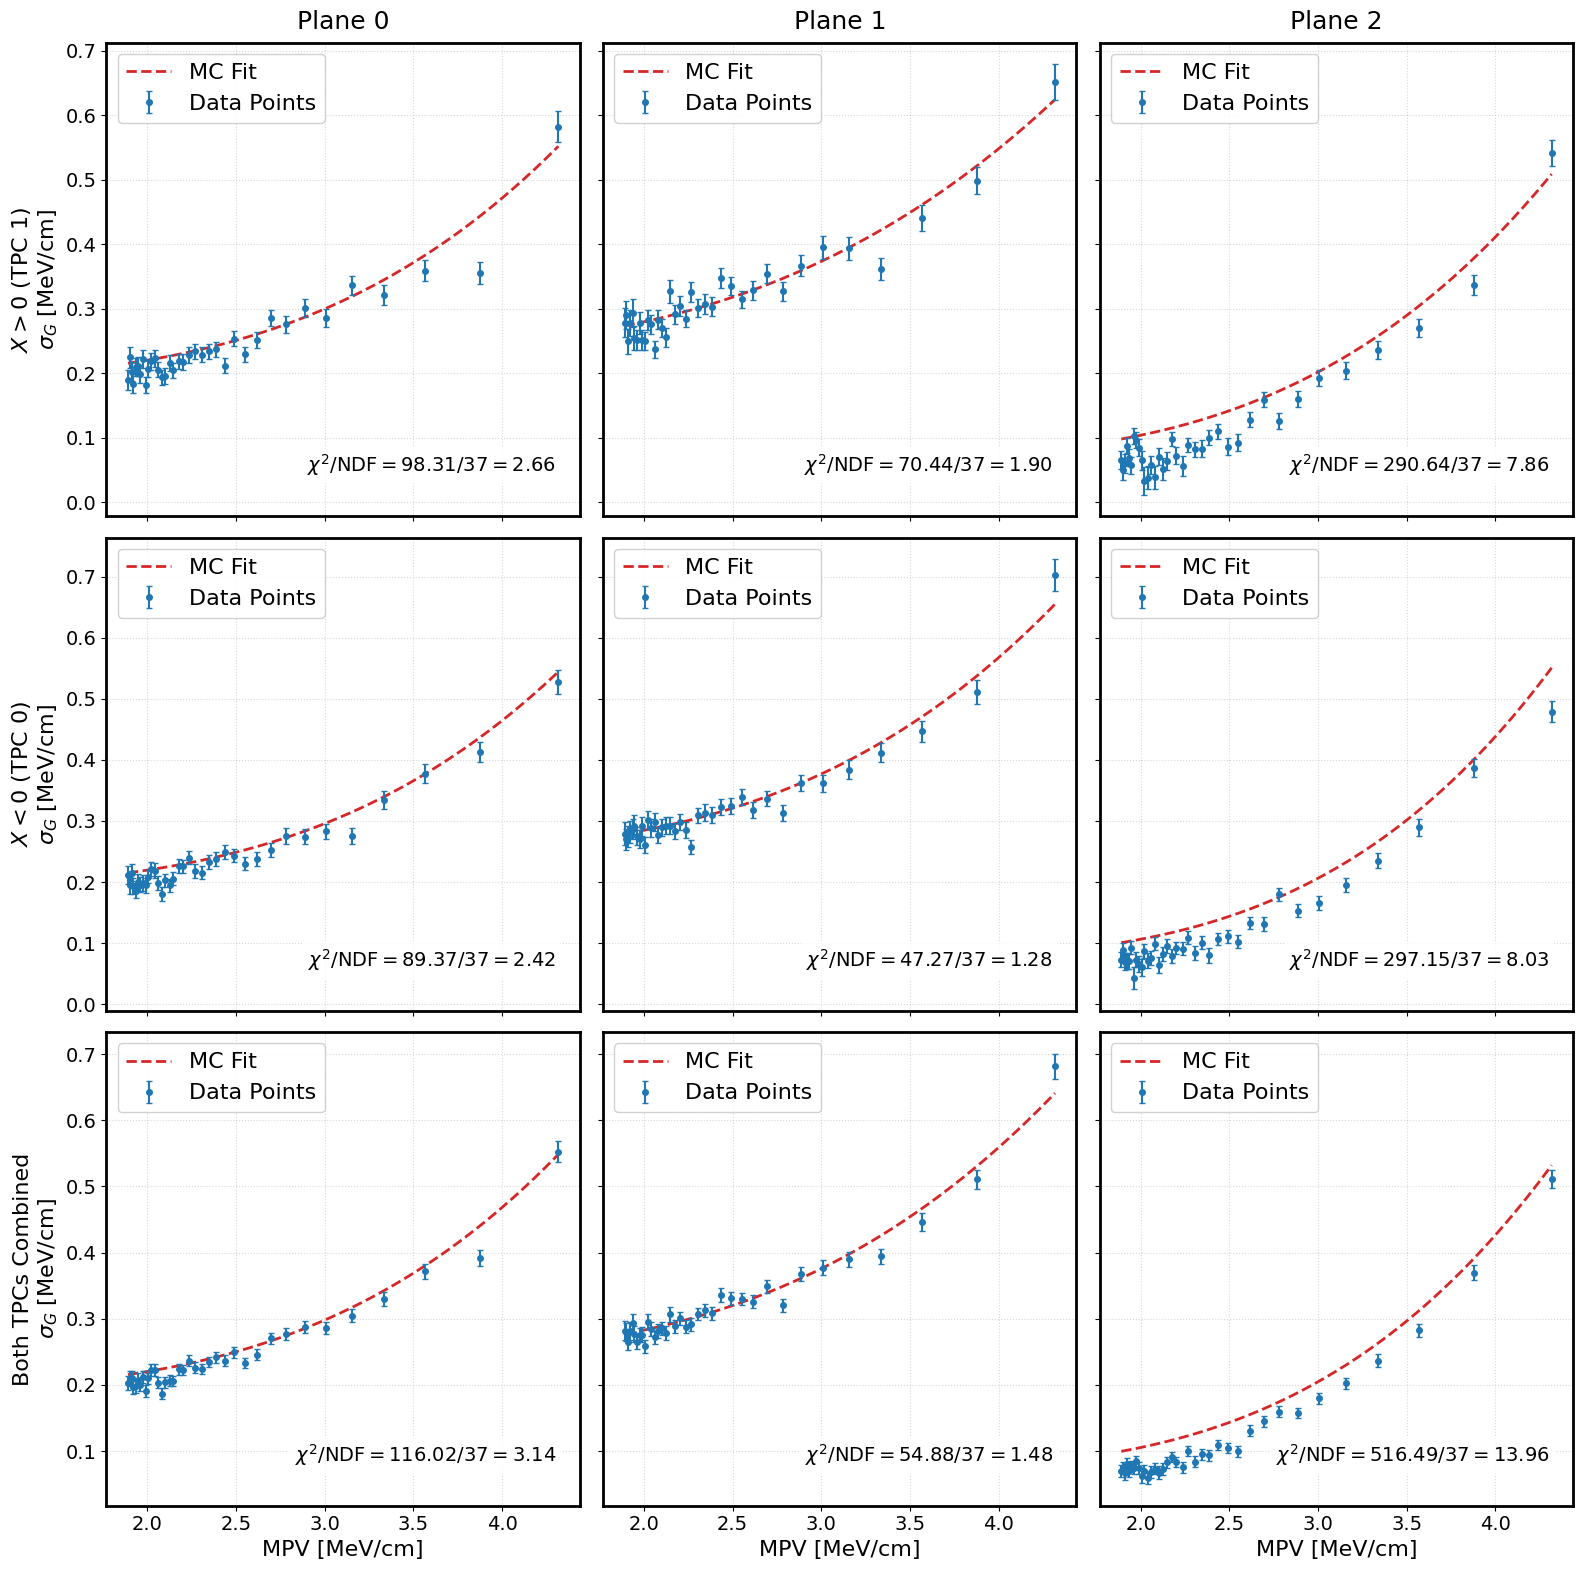

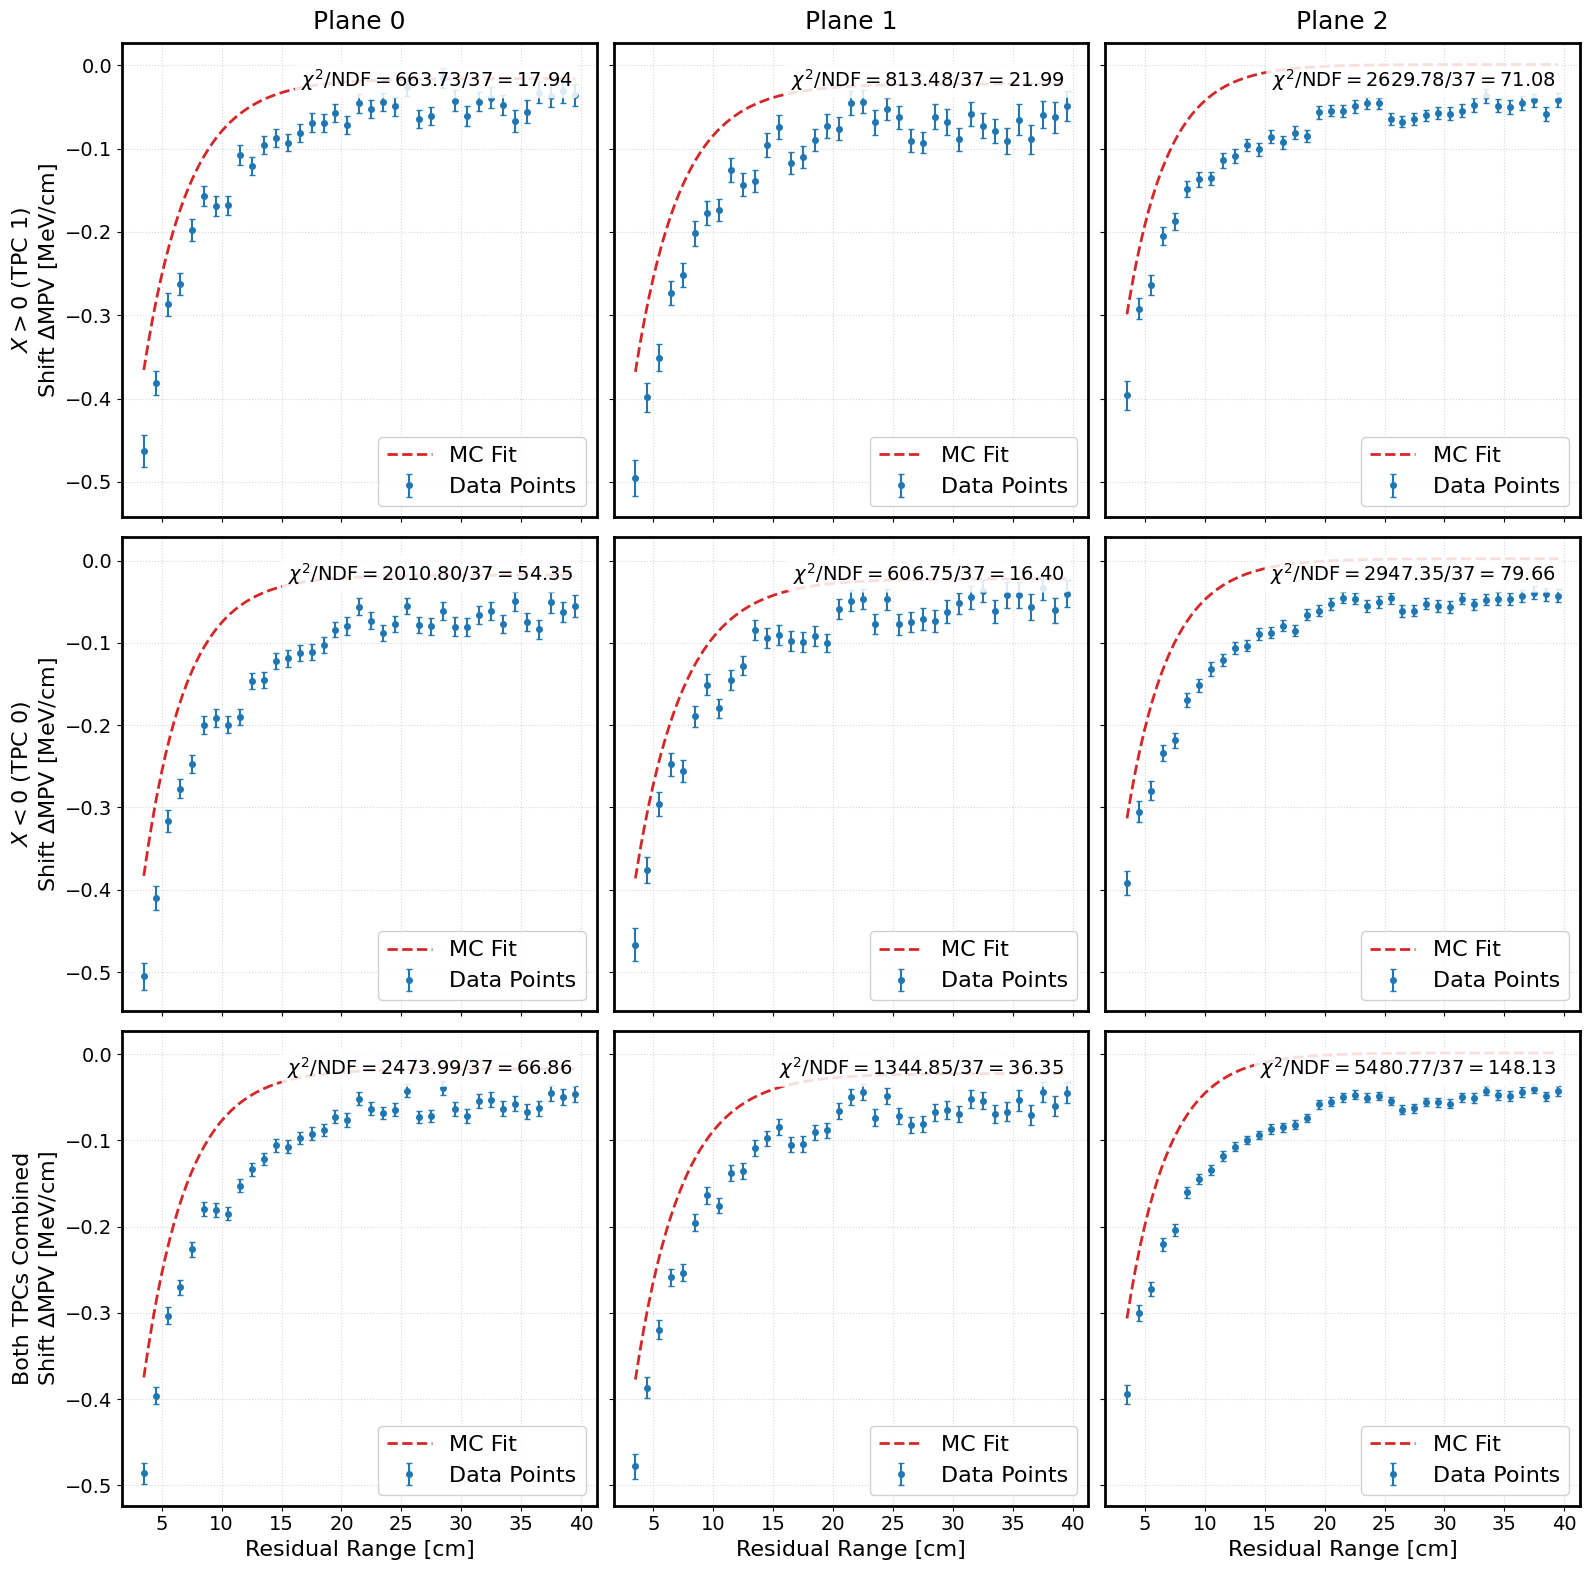

In [19]:
plot_data_vs_mc_fit(
    data_results=data_results,
    mc_results=mc_results,
    mc_params=mc_sigma_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
)

plot_data_vs_mc_fit_shift(
    data_results=data_results,
    mc_results=mc_results,
    mc_params=mc_shift_fit_params,
    particle=particle,
    out_prefix=  output_dir + "/convolution_fit_" + particle,
)


In [20]:
# ===========================================================================
# Generate C++ literals for pdg_plane_map / pdg_plane_shift_map (MC) and
# pdg_plane_map_data / pdg_plane_shift_map_data (data), from
# sigma_fit_params / shift_fit_params returned by analyze_theoretical().
#
# Only overwrites the entries for the pdg you just fit, and even then only
# where a fit actually converged this run -- anything that fit=None (failed
# convergence) or wasn't the target pdg keeps whatever's in EXISTING_ALL_TXT.
#
# To update before your next run: copy ALL FOUR blocks straight out of
# PhysdEdx.cpp as one paste into EXISTING_ALL_TXT below -- no need to split
# them apart, and no manual re-typing into dicts.
# ===========================================================================

import re

N_PLANES = 3
PDG_LIST = [13, 2212, 211]   # keep this order to match existing map style
TPC = -1                     # -1 = combined TPCs; the arg you're using downstream


def find_balanced_brace(text, open_idx):
    """Given text[open_idx] == '{', return the index of its matching '}',
    correctly handling arbitrary nesting depth (regex alone can't do this)."""
    assert text[open_idx] == '{', f"expected '{{' at index {open_idx}, got {text[open_idx]!r}"
    depth = 0
    for i in range(open_idx, len(text)):
        if text[i] == '{':
            depth += 1
        elif text[i] == '}':
            depth -= 1
            if depth == 0:
                return i
    raise ValueError("Unbalanced braces in C++ text -- check the pasted block")


def parse_cpp_map(cpp_text):
    """Parse a single 'vector<std::map<int, vector<double>>> ... = { ... };' body
    (the {...} block itself, no outer 'vector<...> Name =' wrapper) and
    return dict[(plane, pdg)] -> (a, b, c). Uses explicit brace-depth
    tracking instead of regex, since the structure is 3 levels deep
    (vector{ plane{ entry{ triplet{} } } }) and Python's re can't match
    nested braces reliably."""
    text = cpp_text.strip()
    assert text.startswith('{'), "expected block to start with '{'"
    outer_end = find_balanced_brace(text, 0)
    outer_content = text[1:outer_end]

    result = {}
    plane_idx = -1
    i = 0
    n = len(outer_content)
    while i < n:
        if outer_content[i] == '{':
            plane_end = find_balanced_brace(outer_content, i)
            plane_text = outer_content[i + 1:plane_end]
            plane_idx += 1

            j = 0
            m = len(plane_text)
            while j < m:
                if plane_text[j] == '{':
                    entry_end = find_balanced_brace(plane_text, j)
                    entry_text = plane_text[j + 1:entry_end]  # e.g. "211, {0.18325785, 0.0030161048, 3.2302248}"
                    entry_match = re.match(
                        r'\s*(-?\d+)\s*,\s*\{([^{}]*)\}\s*$', entry_text
                    )
                    if entry_match:
                        pdg_str, triplet_str = entry_match.groups()
                        parts = [p.strip() for p in triplet_str.split(',')]
                        if len(parts) == 3:
                            try:
                                a, b, c = (float(p) for p in parts)
                                result[(plane_idx, int(pdg_str))] = (a, b, c)
                            except ValueError:
                                pass
                    j = entry_end + 1
                else:
                    j += 1
            i = plane_end + 1
        else:
            i += 1
    return result


def parse_all_cpp_maps(all_text):
    """Splits one big pasted chunk containing multiple
    'vector<std::map<int, vector<double>>> PhysdEdx::<name> = { ... };'
    blocks into dict[name] -> parse_cpp_map(...) result, keyed by the
    variable name (e.g. 'pdg_plane_map', 'pdg_plane_map_data')."""
    maps = {}
    for m in re.finditer(r'PhysdEdx::(\w+)\s*=\s*', all_text):
        name = m.group(1)
        brace_start = all_text.index('{', m.end())
        brace_end = find_balanced_brace(all_text, brace_start)
        body = all_text[brace_start:brace_end + 1]
        maps[name] = parse_cpp_map(body)
    return maps


# --- Paste ALL FOUR current PhysdEdx.cpp blocks here as one chunk, in any order ---

EXISTING_ALL_TXT = """

vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_map = {
  // Plane 0
  {
    {13, {0.14239127, 0.007574283, 3.0387078}},
    {2212, {-1, -1, -1}},
    {211, {0.19342207, 0.0026053117, 3.3601791}}
  },
  // Plane 1
  {
    {13, {0.19833565, 0.0098315159, 2.8896978}},
    {2212, {-1, -1, -1}},
    {211, {0.2444265, 0.0046725243, 3.0363741}}
  },
  // Plane 2
  {
    {13, {0.046899734, 0.0051396115, 3.3410388}},
    {2212, {-1, -1, -1}},
    {211, {0.072227891, 0.0030891832, 3.4204308}}
  }
};

vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_shift_map = {
  // Plane 0
  {
    {13, {0.014364484, -0.39140505, 6.8488855}},
    {2212, {-1, -1, -1}},
    {211, {-0.016998084, -0.93561805, 3.6427571}}
  },
  // Plane 1
  {
    {13, {0.0064494297, -0.47022613, 6.4193064}},
    {2212, {-1, -1, -1}},
    {211, {-0.022293774, -0.87420722, 3.8857692}}
  },
  // Plane 2
  {
    {13, {0.0056085459, -0.23560982, 6.7604309}},
    {2212, {-1, -1, -1}},
    {211, {0.0015916355, -0.84947135, 3.4513382}}
  }
};

vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_map_data = {
  // Plane 0
  {
    {13, {0.1431099, 0.005111082, 3.293785}},
    {2212, {-1, -1, -1}},
    {211, {0.17006244, 0.0048448422, 2.9276276}}
  },
  // Plane 1
  {
    {13, {0.21409109, 0.0059681254, 3.2682334}},
    {2212, {-1, -1, -1}},
    {211, {0.25001509, 0.0032153943, 3.2902294}}
  },
  // Plane 2
  {
    {13, {2.3283896e-18, 0.0080824503, 3.1037726}},
    {2212, {-1, -1, -1}},
    {211, {0.03632486, 0.003460479, 3.367582}}
  }
};

vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_shift_map_data = {
  // Plane 0
  {
    {13, {-0.0084319398, -0.4555194, 10.058967}},
    {2212, {-1, -1, -1}},
    {211, {-0.057187877, -0.77567604, 5.2097971}}
  },
  // Plane 1
  {
    {13, {-0.012287711, -0.47588277, 10.737676}},
    {2212, {-1, -1, -1}},
    {211, {-0.061211541, -0.81367363, 4.9102044}}
  },
  // Plane 2
  {
    {13, {-0.0089006432, -0.32902245, 11.700444}},
    {2212, {-1, -1, -1}},
    {211, {-0.048480585, -0.62156304, 5.2789952}}
  }
};

"""

_all_maps = parse_all_cpp_maps(EXISTING_ALL_TXT)
EXISTING_SIGMA_MAP = _all_maps.get("pdg_plane_map", {})
EXISTING_SHIFT_MAP = _all_maps.get("pdg_plane_shift_map", {})
EXISTING_SIGMA_MAP_DATA = _all_maps.get("pdg_plane_map_data", {})
EXISTING_SHIFT_MAP_DATA = _all_maps.get("pdg_plane_shift_map_data", {})

print("Parsed entry counts:",
      {k: len(v) for k, v in _all_maps.items()})  # sanity check -- should be 9 each (3 planes x 3 pdgs)


def fmt_triplet(popt):
    if popt is None:
        return "-1, -1, -1"
    a, b, c = popt
    return f"{a:.8g}, {b:.8g}, {c:.8g}"


def build_map_literal(var_name, existing_map, fit_params, target_pdg, tpc=-1):
    """existing_map: dict[(plane, pdg)] -> (a,b,c) triplet, used as the source
    of truth for any (plane, pdg) not being freshly updated -- including the
    target pdg itself when this run's fit for that plane didn't converge.
    fit_params: dict[(plane, tpc)] -> (popt, perr), as returned by analyze_theoretical."""
    lines = [f"vector<std::map<int, vector<double>>> PhysdEdx::{var_name} = {{"]
    for plane in range(N_PLANES):
        lines.append(f"  // Plane {plane}")
        lines.append("  {")
        for i_pdg, this_pdg in enumerate(PDG_LIST):
            if this_pdg == target_pdg:
                popt, perr = fit_params.get((plane, tpc), (None, None))
                if popt is not None:
                    triplet = fmt_triplet(popt)
                else:
                    triplet = fmt_triplet(existing_map.get((plane, this_pdg)))
                    print(f"  [warn] no fit for plane={plane}, tpc={tpc}, pdg={this_pdg} "
                          f"-> keeping existing value ({triplet})")
            else:
                triplet = fmt_triplet(existing_map.get((plane, this_pdg)))
            comma = "," if i_pdg < len(PDG_LIST) - 1 else ""
            lines.append(f"    {{{this_pdg}, {{{triplet}}}}}{comma}")
        comma_plane = "," if plane < N_PLANES - 1 else ""
        lines.append(f"  }}{comma_plane}")
    lines.append("};")
    return "\n".join(lines)

# --- MC ---
print(build_map_literal("pdg_plane_map", EXISTING_SIGMA_MAP, mc_sigma_fit_params, pdg, tpc=TPC))
print()
print(build_map_literal("pdg_plane_shift_map", EXISTING_SHIFT_MAP, mc_shift_fit_params, pdg, tpc=TPC))
print()

# --- Data ---
print(build_map_literal("pdg_plane_map_data", EXISTING_SIGMA_MAP_DATA, data_sigma_fit_params, pdg, tpc=TPC))
print()
print(build_map_literal("pdg_plane_shift_map_data", EXISTING_SHIFT_MAP_DATA, data_shift_fit_params, pdg, tpc=TPC))

Parsed entry counts: {'pdg_plane_map': 9, 'pdg_plane_shift_map': 9, 'pdg_plane_map_data': 9, 'pdg_plane_shift_map_data': 9}
vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_map = {
  // Plane 0
  {
    {13, {0.14239127, 0.007574283, 3.0387078}},
    {2212, {-1, -1, -1}},
    {211, {0.19342207, 0.0026053117, 3.3601791}}
  },
  // Plane 1
  {
    {13, {0.19833565, 0.0098315159, 2.8896978}},
    {2212, {-1, -1, -1}},
    {211, {0.2444265, 0.0046725243, 3.0363741}}
  },
  // Plane 2
  {
    {13, {0.046899734, 0.0051396115, 3.3410388}},
    {2212, {-1, -1, -1}},
    {211, {0.072227891, 0.0030891832, 3.4204308}}
  }
};

vector<std::map<int, vector<double>>> PhysdEdx::pdg_plane_shift_map = {
  // Plane 0
  {
    {13, {0.014364484, -0.39140505, 6.8488855}},
    {2212, {-1, -1, -1}},
    {211, {-0.016998084, -0.93561805, 3.6427571}}
  },
  // Plane 1
  {
    {13, {0.0064494297, -0.47022613, 6.4193064}},
    {2212, {-1, -1, -1}},
    {211, {-0.022293774, -0.87420722, 3.8857692}}
  },
  